# Temporal Network Analysis of Mexican Drug Trafficking Organizations (1990–2010)

**Core Research Question (Project Description):** *Can temporal network structures predict the formation of new cartel–municipality connections, and what patterns are associated with their emergence?*

**Operationalization & Hypotheses:**
To test how network structure and inter-cartel dynamics drive link emergence (and subsequent persistence or disappearance), we evaluate four hypotheses across annual bipartite snapshots from 1990 to 2010 (Coscia & Rios, 2012):
- **H1 (Within-state path dependence):** A new cartel–municipality association is more likely when the cartel is already active elsewhere in the same state.
- **H2 (Rival deterrence vs. co-presence):** A new association is less likely when the municipality already hosts a rival cartel that significantly avoids the focal cartel.
- **H3 (Displacement / disappearance):** An existing association is more likely to disappear at $t+1$ when an avoiding rival is present in the same municipality at $t$.
- **H4 (Organization heterogeneity):** Expansion, co-presence, and disappearance patterns vary substantially across individual cartels.

**Pipeline Structure (Aligned with Project Plan):**
1. **Temporal Bipartite Network Construction (1990–2010):** Validate the dataset and construct 21 annual undirected, unweighted bipartite graphs (`networks_by_year`) across the 9 specific cartels (retaining `Otros` separately for sensitivity checks).
2. **Exploratory Network Analysis (1990–2010):** Analyze longitudinal network growth, bipartite density, degree distributions, edge turnover, and cartel overlap against degree-preserving and state-stratified null models.
3. **Temporal Link Prediction (Emergence of New Connections):** Engineer leak-free historical, structural, and territorial features; evaluate predictive models across chronological splits (2007–2008 development, 2009–2010 held-out test); and estimate state-clustered binomial GLMs.
4. **Extensions & Robustness:** Test link disappearance (H3), cartel-level heterogeneity (H4), and robustness checks (including `Otros` and restricting to first-observed links).
5. **Mesoscale Structure & Network Intervention Simulation:** Extract municipality backbones and Louvain communities, compute node/edge centrality, and simulate targeted network interventions.

## 1. Data Loading, Validation & Temporal Bipartite Network Construction

Each annual snapshot is an **undirected, unweighted bipartite network** connecting municipality nodes (`bipartite=0`) to cartel nodes (`bipartite=1`) whenever the CSV indicator equals 1. Because `Otros` is an aggregate catch-all category rather than an individual cartel, it is validated during loading and excluded from `organization_columns` in the main network so it does not distort cartel degree distributions or overlap z-scores (it is retained in `all_organization_columns` for sensitivity checks).

In [1]:
from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, normalized_mutual_info_score
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod.families import Binomial
from IPython.display import display, Image

# Resolve dataset path across project root, subdirectories, or explicit Windows path.
csv_candidates = [
    Path.cwd() / "data" / "CosciaRios2012_DataBase.csv",
    Path.cwd().parent / "data" / "CosciaRios2012_DataBase.csv",
    Path.cwd() / "CosciaRios2012_DataBase.csv",
    Path(r"C:\Users\quaqm\Desktop\NetworkAnalysis_Project-1\data\CosciaRios2012_DataBase.csv"),
]
csv_path = next((p for p in csv_candidates if p.exists()), csv_candidates[-1])

data = pd.read_csv(
    csv_path,
    dtype={"Code": "string", "State": "string"},
)
all_organization_columns = data.columns.drop(["Code", "State", "Year"]).tolist()

assert not data.isna().any().any(), "Missing values require inspection."
assert not data.duplicated(["Code", "Year"]).any(), "Duplicate municipality-year rows."
assert data[all_organization_columns].isin([0, 1]).all().all(), "Expected binary associations."

# Exclude aggregate catch-all 'Otros' from the primary cartel set; retain for sensitivity checks.
organization_columns = [col for col in all_organization_columns if col != "Otros"]

print(
    f"Validated {len(data):,} municipality-year records ({data['Year'].min()}–{data['Year'].max()}) | "
    f"{data['Code'].nunique():,} distinct municipalities | {len(organization_columns)} cartels (+ 'Otros' for sensitivity)"
)

Validated 51,596 municipality-year records (1990–2010) | 2,457 distinct municipalities | 9 cartels (+ 'Otros' for sensitivity)


In [2]:
def build_annual_network(year_data, year, org_cols=organization_columns):
    graph = nx.Graph(year=int(year))
    graph.add_nodes_from(
        (f"organization:{name}", {"bipartite": 1, "node_type": "organization", "label": name})
        for name in org_cols
    )
    for _, row in year_data.iterrows():
        municipality = f"municipality:{row['Code']}"
        graph.add_node(
            municipality,
            bipartite=0,
            node_type="municipality",
            code=row["Code"],
            state=row["State"],
            label=row["Code"],
        )
        graph.add_edges_from(
            (municipality, f"organization:{name}")
            for name in org_cols
            if row[name] == 1
        )
    return graph

networks_by_year = {
    int(year): build_annual_network(year_data, year)
    for year, year_data in data.groupby("Year", sort=True)
}
years = sorted(networks_by_year)

assert all(nx.is_bipartite(g) for g in networks_by_year.values())
assert all(
    g.nodes[u]["bipartite"] != g.nodes[v]["bipartite"]
    for g in networks_by_year.values()
    for u, v in g.edges()
)
print(f"Constructed {len(networks_by_year)} annual bipartite graphs in `networks_by_year` ({years[0]}–{years[-1]}).")

Constructed 21 annual bipartite graphs in `networks_by_year` (1990–2010).


## 2. Exploratory Network Analysis (1990–2010)

### 2.1 Network Growth, Bipartite Density & Concentration Over Time

Rather than focusing on a single static snapshot, we track network size, active municipalities, **bipartite density** (edges divided by all possible municipality–cartel pairs), multi-cartel overlap share, and the Herfindahl–Hirschman Index (HHI) of cartel degree shares across the entire 1990–2010 period.

,nodes,municipalities,cartels,edges,active_municipalities,active_cartels,isolates,largest_component_nodes,average_degree,bipartite_density,active_municipality_pct,overlapping_municipalities,overlap_pct_among_active,mean_degree_active_municipalities,largest_cartel_share,concentration_hhi
year,,,,,,,,,,,,,,,,
1990,2466,2457,9,0,0,0,2466,1,0.0000,0.0000,0.0000,0,0.0000,0.0000,NaN,NaN
1991,2466,2457,9,6,6,2,2458,4,0.0049,0.0003,0.2442,0,0.0000,1.0000,0.5000,0.5000
1992,2466,2457,9,6,5,3,2458,6,0.0049,0.0003,0.2035,1,20.0000,1.2000,0.5000,0.3889
1993,2466,2457,9,24,22,5,2439,15,0.0195,0.0011,0.8954,2,9.0909,1.0909,0.5000,0.3368
1994,2466,2457,9,31,29,4,2433,30,0.0251,0.0014,1.1803,2,6.8966,1.0690,0.4194,0.3215
1995,2466,2457,9,23,20,4,2442,16,0.0187,0.0010,0.8140,3,15.0000,1.1500,0.3043,0.2628
1996,2466,2457,9,36,31,6,2429,35,0.0292,0.0016,1.2617,5,16.1290,1.1613,0.3056,0.2562
1997,2466,2457,9,51,48,6,2412,25,0.0414,0.0023,1.9536,3,6.2500,1.0625,0.3725,0.2672
1998,2466,2457,9,49,43,5,2418,48,0.0397,0.0022,1.7501,6,13.9535,1.1395,0.3673,0.2403


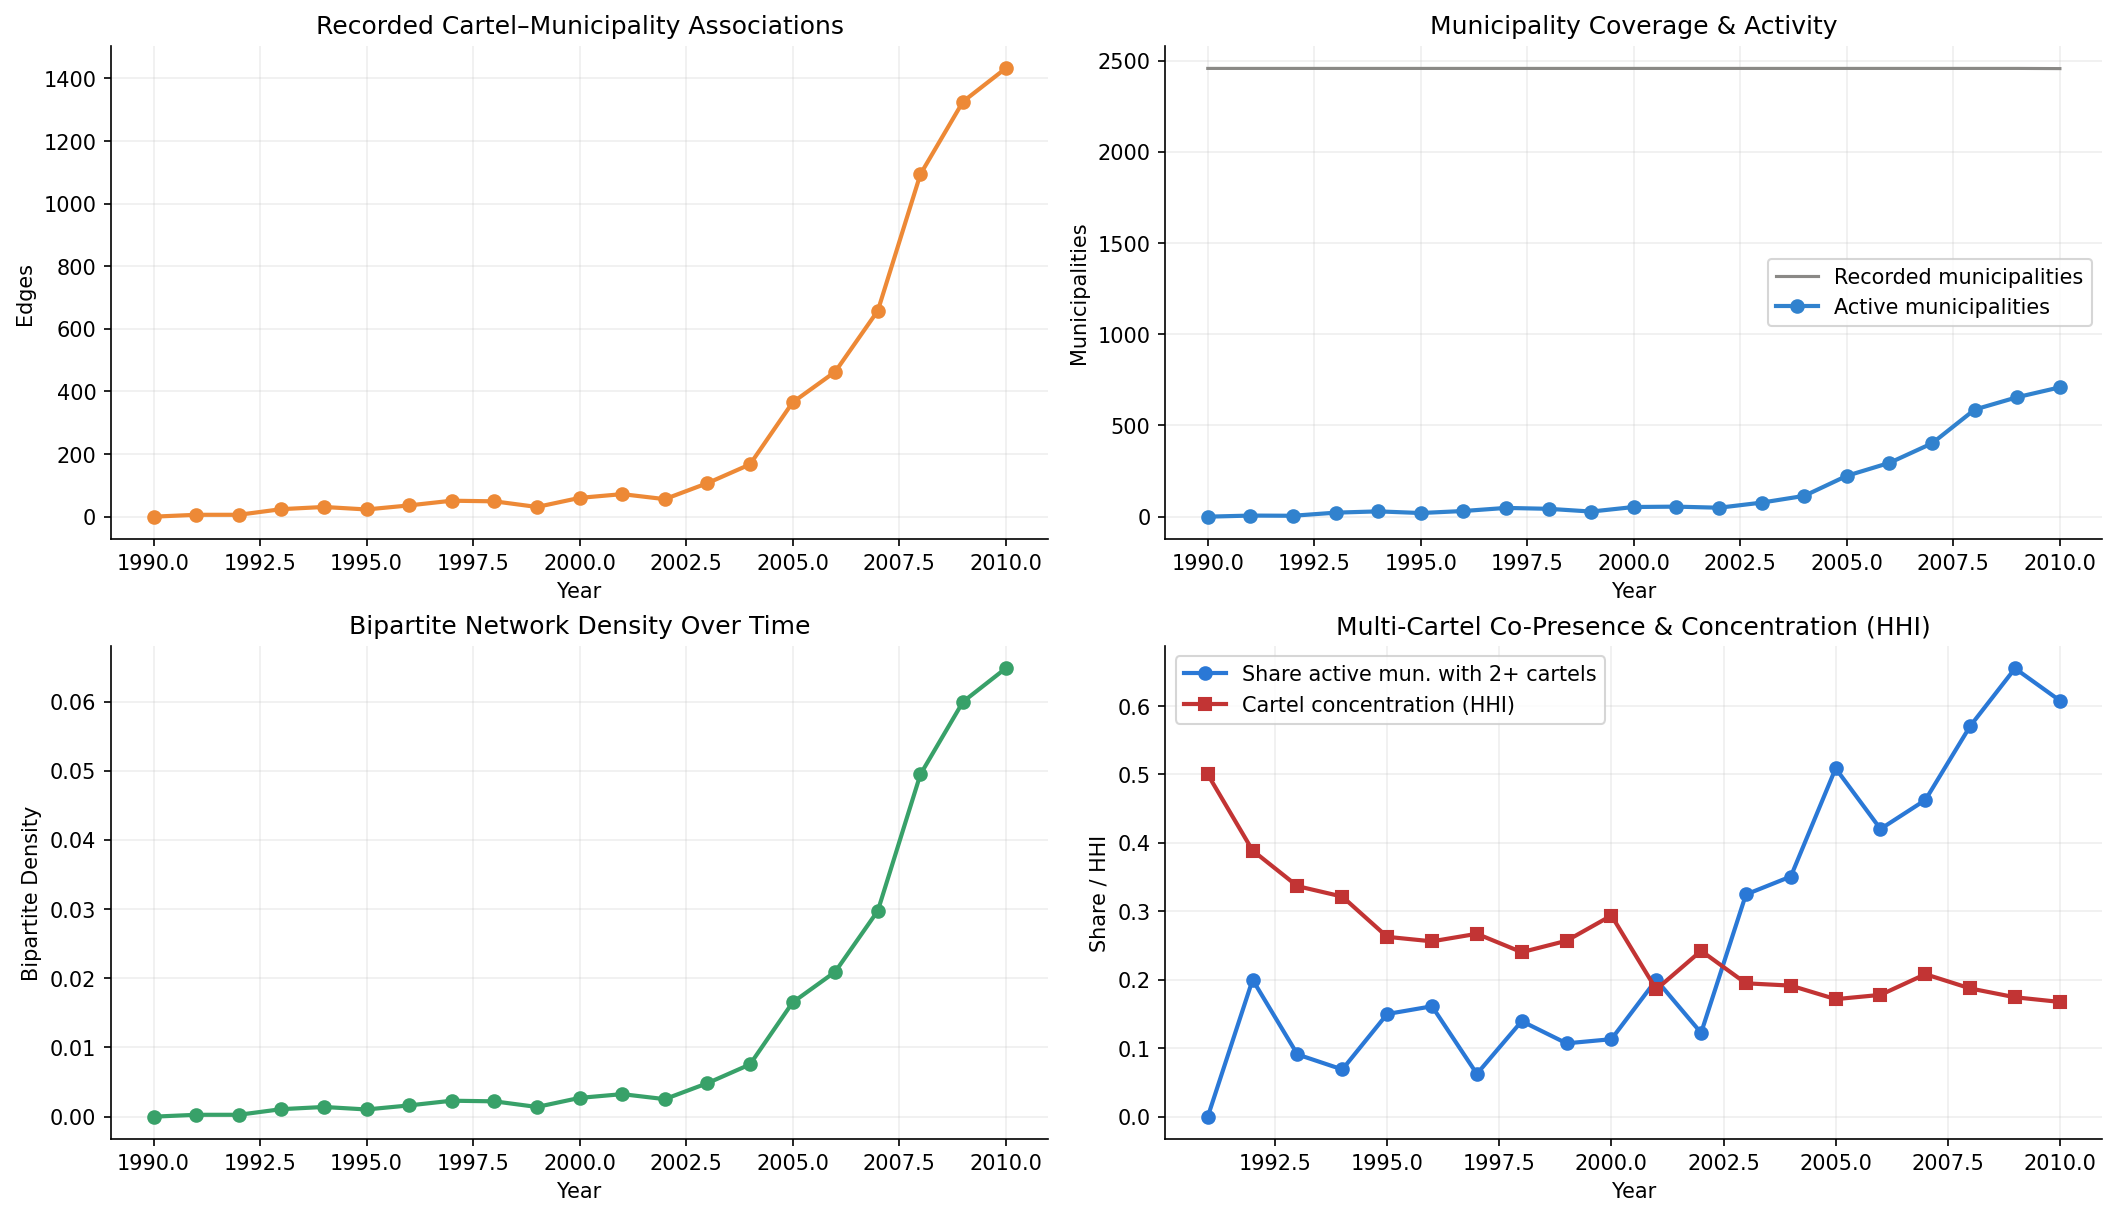

In [3]:
def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

def annual_network_metrics(graph):
    municipalities = [n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0]
    cartels = [n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 1]
    m_degrees = [graph.degree(v) for v in municipalities]
    c_degrees = np.array([graph.degree(c) for c in cartels], dtype=float)
    n, m = graph.number_of_nodes(), graph.number_of_edges()
    active_m = sum(d > 0 for d in m_degrees)
    overlap_m = sum(d >= 2 for d in m_degrees)
    components = list(nx.connected_components(graph))
    largest = max(components, key=len, default=set())
    total_c_deg = c_degrees.sum()
    shares = c_degrees / total_c_deg if total_c_deg > 0 else np.zeros_like(c_degrees)
    return {
        "nodes": n,
        "municipalities": len(municipalities),
        "cartels": len(cartels),
        "edges": m,
        "active_municipalities": active_m,
        "active_cartels": int((c_degrees > 0).sum()),
        "isolates": nx.number_of_isolates(graph),
        "largest_component_nodes": len(largest),
        "average_degree": 2 * m / n if n else 0.0,
        "bipartite_density": bipartite.density(graph, municipalities),
        "active_municipality_pct": 100 * active_m / len(municipalities) if municipalities else 0.0,
        "overlapping_municipalities": overlap_m,
        "overlap_pct_among_active": 100 * overlap_m / active_m if active_m else 0.0,
        "mean_degree_active_municipalities": sum(m_degrees) / active_m if active_m else 0.0,
        "largest_cartel_share": float(shares.max()) if total_c_deg > 0 else np.nan,
        "concentration_hhi": float((shares ** 2).sum()) if total_c_deg > 0 else np.nan,
    }

annual_stats = pd.DataFrame.from_dict(
    {year: annual_network_metrics(graph) for year, graph in networks_by_year.items()},
    orient="index",
).rename_axis("year")
display(annual_stats.round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
axes[0, 0].plot(annual_stats.index, annual_stats["edges"], marker="o", color="#ed8936", lw=2)
axes[0, 0].set(title="Recorded Cartel–Municipality Associations", xlabel="Year", ylabel="Edges")

axes[0, 1].plot(annual_stats.index, annual_stats["municipalities"], label="Recorded municipalities", color="#8a8986")
axes[0, 1].plot(annual_stats.index, annual_stats["active_municipalities"], marker="o", label="Active municipalities", color="#3182ce", lw=2)
axes[0, 1].set(title="Municipality Coverage & Activity", xlabel="Year", ylabel="Municipalities")
axes[0, 1].legend()

axes[1, 0].plot(annual_stats.index, annual_stats["bipartite_density"], marker="o", color="#38a169", lw=2)
axes[1, 0].set(title="Bipartite Network Density Over Time", xlabel="Year", ylabel="Bipartite Density")

active_years = annual_stats.dropna(subset=["concentration_hhi"])
axes[1, 1].plot(active_years.index, active_years["overlap_pct_among_active"] / 100.0, marker="o", color="#2a78d6", lw=2, label="Share active mun. with 2+ cartels")
axes[1, 1].plot(active_years.index, active_years["concentration_hhi"], marker="s", color="#c23434", lw=2, label="Cartel concentration (HHI)")
axes[1, 1].set(title="Multi-Cartel Co-Presence & Concentration (HHI)", xlabel="Year", ylabel="Share / HHI")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 2.2 Longitudinal Degree Distributions (1990–2010)

In a bipartite cartel–municipality network, degree distributions have two distinct sides:
- **Cartel degree trajectories:** Number of municipalities associated with each cartel over time.
- **Municipality degree distribution:** Share and count of municipalities hosting 0, 1, 2, or 3+ cartels across years.

,Beltrán Leyva,BL Family,Familia,Gulf,Juárez,Sinaloa,Sinaloa Family,Tijuana,Zetas
year,,,,,,,,,
2000,0,0,0,24,7,17,0,12,0
2001,10,0,0,9,11,21,4,14,3
2002,0,0,0,10,15,12,1,17,1
2003,5,0,0,31,17,15,1,17,21
2004,11,0,5,41,18,38,0,15,39
2005,49,0,24,86,35,73,6,17,75
2006,43,7,46,112,29,75,1,31,119
2007,48,9,31,190,42,109,10,29,190
2008,108,26,118,265,49,142,37,28,321


,deg_0_isolated,deg_1_single,deg_2_dual,deg_3_plus
year,,,,
2000,2404,47,5,1
2001,2402,44,6,5
2002,2408,43,5,1
2003,2380,52,21,4
2004,2343,74,28,12
2005,2233,110,88,26
2006,2162,171,90,34
2007,2055,216,131,55
2008,1870,252,223,112


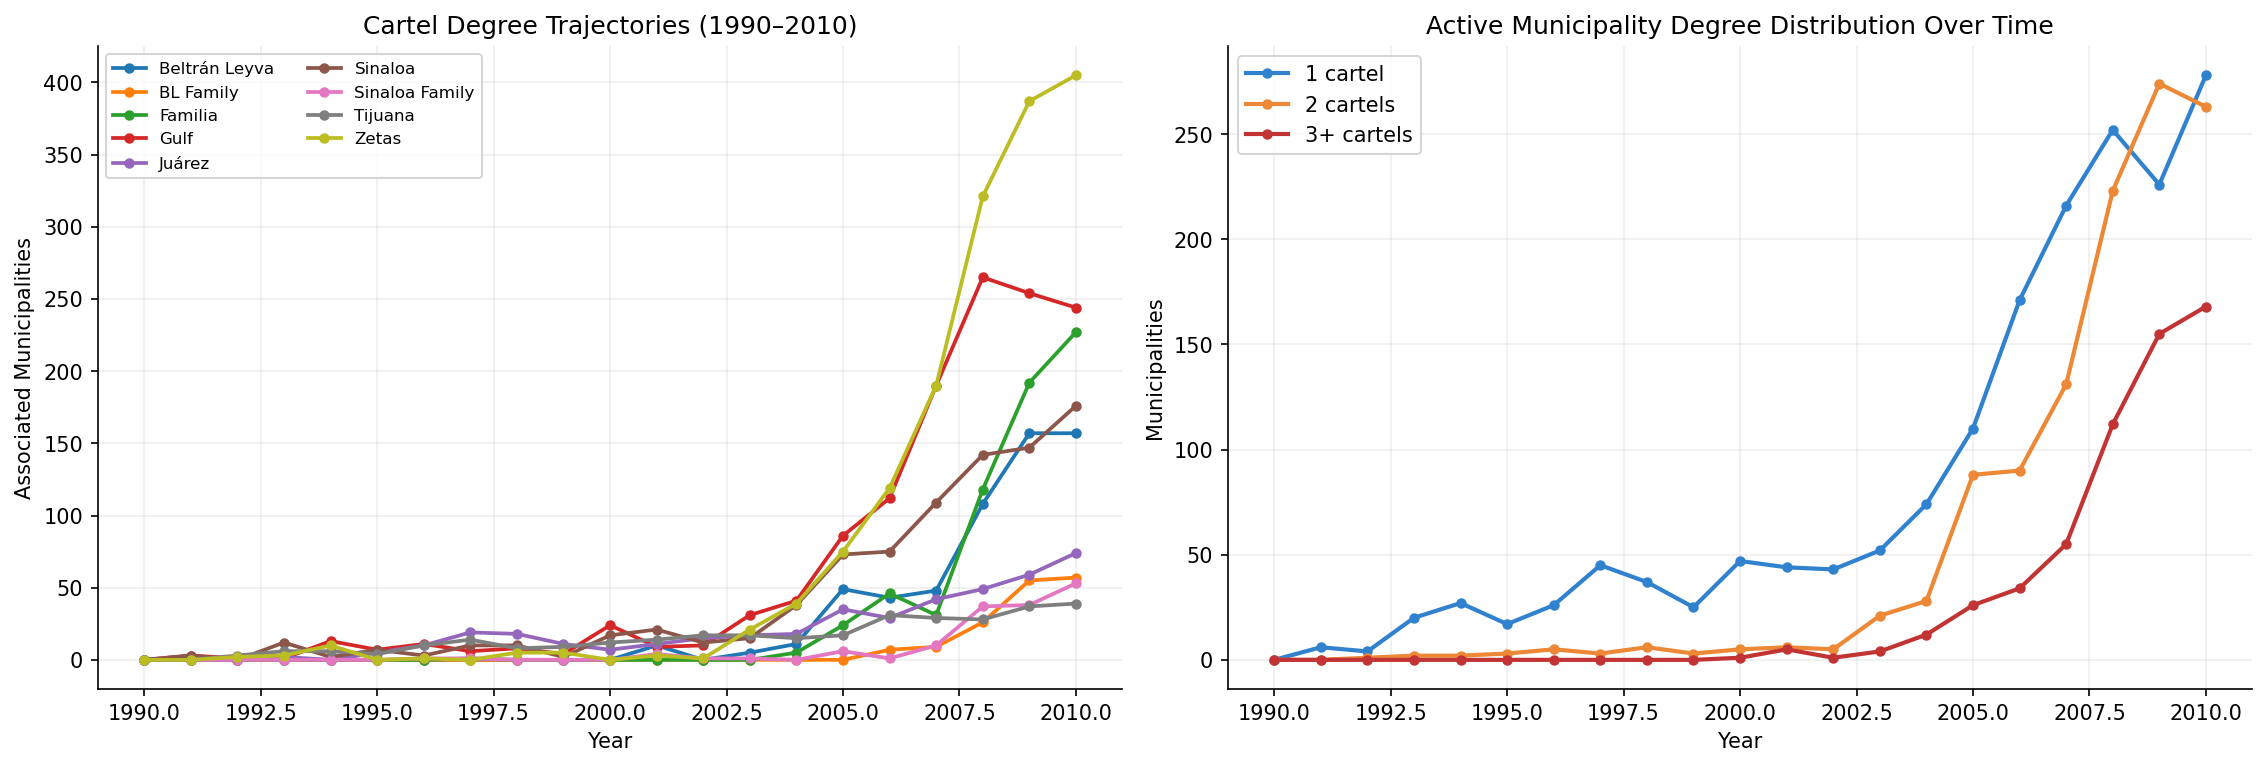

In [4]:
display_names = {
    "Beltran_Leyva": "Beltrán Leyva",
    "Beltran_Leyva_Family": "BL Family",
    "Familia": "Familia",
    "Golfo": "Gulf",
    "Juarez": "Juárez",
    "Sinaloa": "Sinaloa",
    "Sinaloa_Family": "Sinaloa Family",
    "Tijuana": "Tijuana",
    "Zetas": "Zetas",
    "Otros": "Otros",
}

cartel_degrees_by_year = pd.DataFrame(
    {
        year: {
            display_names[col]: networks_by_year[year].degree(f"organization:{col}")
            for col in organization_columns
        }
        for year in years
    }
).T.rename_axis("year")

mun_deg_rows = []
for year, graph in networks_by_year.items():
    m_degs = pd.Series([graph.degree(n) for n, d in graph.nodes(data=True) if d["bipartite"] == 0])
    mun_deg_rows.append({
        "year": year,
        "deg_0_isolated": int((m_degs == 0).sum()),
        "deg_1_single": int((m_degs == 1).sum()),
        "deg_2_dual": int((m_degs == 2).sum()),
        "deg_3_plus": int((m_degs >= 3).sum()),
    })
municipality_degree_dist_by_year = pd.DataFrame(mun_deg_rows).set_index("year")

display(cartel_degrees_by_year.loc[2000:])
display(municipality_degree_dist_by_year.loc[2000:])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for col in cartel_degrees_by_year.columns:
    axes[0].plot(cartel_degrees_by_year.index, cartel_degrees_by_year[col], marker="o", ms=4, lw=1.8, label=col)
axes[0].set(title="Cartel Degree Trajectories (1990–2010)", xlabel="Year", ylabel="Associated Municipalities")
axes[0].legend(fontsize=8, ncol=2, loc="upper left")

for col, label, color in [
    ("deg_1_single", "1 cartel", "#3182ce"),
    ("deg_2_dual", "2 cartels", "#ed8936"),
    ("deg_3_plus", "3+ cartels", "#c23434"),
]:
    axes[1].plot(municipality_degree_dist_by_year.index, municipality_degree_dist_by_year[col], marker="o", ms=4, lw=2, label=label, color=color)
axes[1].set(title="Active Municipality Degree Distribution Over Time", xlabel="Year", ylabel="Municipalities")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 2.3 Connection Changes & Edge Turnover Over Time (1990–2010)

To separate genuine link formation and disappearance from administrative coverage changes, adjacent-year edge transitions are computed strictly on municipalities recorded in **both** year $t-1$ and year $t$.

,shared_municipalities,municipalities_entering_file,municipalities_leaving_file,appearing_associations,persisting_associations,disappearing_associations
year,,,,,,
2000,2457,0,0,53,7,24
2001,2457,0,0,59,13,47
2002,2457,0,0,42,14,58
2003,2457,0,0,89,18,38
2004,2457,0,0,131,36,71
2005,2457,0,0,305,60,107
2006,2457,0,0,350,113,252
2007,2457,0,0,452,206,257
2008,2457,0,0,722,372,286


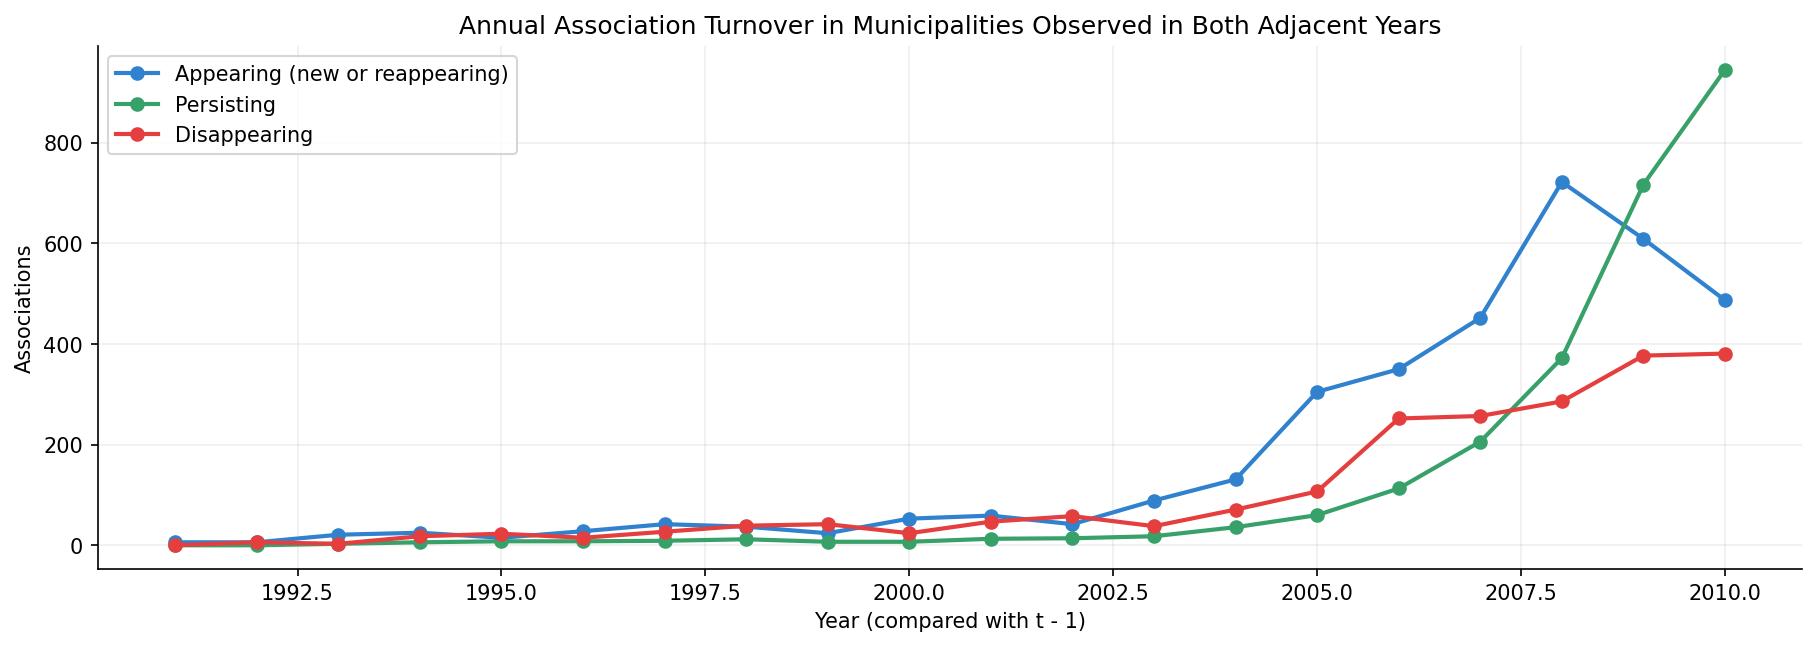

In [5]:
def municipality_set(graph):
    return {n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0}

def association_set(graph, municipalities):
    return {
        (municipality, organization)
        for municipality in municipalities
        for organization in graph.neighbors(municipality)
    }

turnover_records = []
for previous_year, year in zip(years[:-1], years[1:]):
    prev_g, curr_g = networks_by_year[previous_year], networks_by_year[year]
    prev_m, curr_m = municipality_set(prev_g), municipality_set(curr_g)
    shared = prev_m & curr_m
    prev_edges = association_set(prev_g, shared)
    curr_edges = association_set(curr_g, shared)
    turnover_records.append({
        "year": year,
        "shared_municipalities": len(shared),
        "municipalities_entering_file": len(curr_m - prev_m),
        "municipalities_leaving_file": len(prev_m - curr_m),
        "appearing_associations": len(curr_edges - prev_edges),
        "persisting_associations": len(curr_edges & prev_edges),
        "disappearing_associations": len(prev_edges - curr_edges),
    })
turnover_stats = pd.DataFrame(turnover_records).set_index("year")
display(turnover_stats.loc[2000:])

fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
for column, label, color in [
    ("appearing_associations", "Appearing (new or reappearing)", "#3182ce"),
    ("persisting_associations", "Persisting", "#38a169"),
    ("disappearing_associations", "Disappearing", "#e53e3e"),
]:
    ax.plot(turnover_stats.index, turnover_stats[column], marker="o", lw=2, label=label, color=color)
ax.set(
    title="Annual Association Turnover in Municipalities Observed in Both Adjacent Years",
    xlabel="Year (compared with t - 1)",
    ylabel="Associations",
)
ax.legend()
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 2.4 Cartel Overlap, Null Models & Rivalry Scores (1990–2010)

Projecting the bipartite graph onto the 9 cartels counts how many active municipalities two cartels share. Because raw overlap reflects overall cartel size and regional concentration, we compare observed co-presence against two Curveball configuration-model nulls (Strona et al., 2014):
1. **Degree-preserving null:** Preserves municipality and cartel degrees nationwide.
2. **State-stratified null:** Exchanges links only among municipalities within the same state, controlling for state-level geographic concentration.

We inspect three pivotal focus years—**2006** (start of federal offensive), **2008** (Beltrán Leyva split from Sinaloa), and **2010** (Zetas split from Gulf)—and compute leak-free annual state-stratified z-scores (`rival_z`) from 1990 to 2009 for downstream prediction.

In [ ]:
focus_years = [2006, 2008, 2010]
null_samples = 300
state_names = {
    str(code): name
    for code, name in enumerate([
        "Aguascalientes", "Baja California", "Baja California Sur", "Campeche", "Coahuila", "Colima",
        "Chiapas", "Chihuahua", "Distrito Federal", "Durango", "Guanajuato", "Guerrero", "Hidalgo",
        "Jalisco", "México", "Michoacán", "Morelos", "Nayarit", "Nuevo León", "Oaxaca", "Puebla",
        "Querétaro", "Quintana Roo", "San Luis Potosí", "Sinaloa", "Sonora", "Tabasco", "Tamaulipas",
        "Tlaxcala", "Veracruz", "Yucatán", "Zacatecas",
    ], start=1)
}
diverging_cmap = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#f0efec", "#c23434"])

def active_records(year, org_cols=organization_columns):
    year_data = data[data["Year"] == year]
    return year_data[year_data[org_cols].sum(axis=1) > 0].reset_index(drop=True)

def curveball_sample(matrix, groups, rng, trades_per_row=5):
    rows = [set(np.flatnonzero(row)) for row in matrix]
    members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    members = [m for m in members if len(m) > 1]
    if not members:
        return matrix.copy()
    sizes = np.array([len(m) for m in members])
    n_trades = trades_per_row * len(rows)
    picked = rng.choice(len(members), size=n_trades, p=sizes / sizes.sum())
    first, second = rng.random(n_trades), rng.random(n_trades)
    for g, u, v in zip(picked, first, second):
        m = members[g]
        a = int(u * len(m))
        b = int(v * (len(m) - 1))
        b += b >= a
        i, j = m[a], m[b]
        only_i, only_j = rows[i] - rows[j], rows[j] - rows[i]
        if not only_i or not only_j:
            continue
        shared = rows[i] & rows[j]
        pool = list(only_i | only_j)
        rng.shuffle(pool)
        rows[i] = shared | set(pool[:len(only_i)])
        rows[j] = shared | set(pool[len(only_i):])
    sample = np.zeros_like(matrix)
    for i, row in enumerate(rows):
        sample[i, list(row)] = 1
    return sample

def overlap_zscores(records, stratify_by_state, seed, org_cols=organization_columns):
    rng = np.random.default_rng(seed)
    matrix = records[org_cols].to_numpy()
    if len(records) < 2:
        zeros = pd.DataFrame(0.0, index=org_cols, columns=org_cols)
        return zeros, matrix.T @ matrix
    groups = records["State"].to_numpy() if stratify_by_state else np.zeros(len(records), dtype=int)
    observed = matrix.T @ matrix
    samples = []
    for _ in range(null_samples):
        s = curveball_sample(matrix, groups, rng)
        samples.append(s.T @ s)
    samples = np.array(samples)
    mean, sd = samples.mean(axis=0), samples.std(axis=0)
    z = np.where(sd > 0, (observed - mean) / np.where(sd > 0, sd, 1), 0.0)
    np.fill_diagonal(z, 0)
    return pd.DataFrame(z, index=org_cols, columns=org_cols), observed

active_by_year = {year: active_records(year) for year in focus_years}
n_pairs = len(organization_columns) * (len(organization_columns) - 1) // 2
critical_z = norm.isf(0.05 / (2 * n_pairs))
print(f"Bonferroni critical |z| for {n_pairs} cartel pairs (α = 0.05): {critical_z:.2f}")

overlap_z, overlap_observed = {}, {}
for k, year in enumerate(focus_years):
    records = active_by_year[year]
    overlap_z[(year, "degree")], overlap_observed[year] = overlap_zscores(records, False, seed=k)
    overlap_z[(year, "state")], _ = overlap_zscores(records, True, seed=100 + k)

# Heatmaps comparing degree-preserving vs. state-stratified null models
labels = [display_names[c] for c in organization_columns]
fig, axes = plt.subplots(2, len(focus_years), figsize=(17, 10.5), constrained_layout=True)
limit = 10
for col, year in enumerate(focus_years):
    for row, (null, title) in enumerate([("degree", "degree-preserving null"), ("state", "state-stratified null")]):
        ax = axes[row, col]
        z = overlap_z[(year, null)].to_numpy()
        masked = np.ma.masked_where(np.eye(len(z), dtype=bool), z)
        image = ax.imshow(masked, cmap=diverging_cmap, vmin=-limit, vmax=limit)
        for i in range(len(z)):
            for j in range(len(z)):
                if i != j:
                    ax.text(
                        j, i, f"{z[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                        fontweight="bold" if abs(z[i, j]) >= critical_z else "normal",
                        color="white" if abs(z[i, j]) > 6 else "#0b0b0b",
                    )
        ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.set_title(f"{year}: {title}", fontsize=11)
        ax.tick_params(length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
fig.colorbar(image, ax=axes, shrink=0.5, label="Overlap z-score (red: more shared municipalities; blue: avoidance)")
fig.suptitle(f"Cartel Co-Presence Against Null Models (bold: |z| ≥ {critical_z:.2f}, Bonferroni α = 0.05)", fontsize=13)
show_figure(fig)

Bonferroni critical |z| for 36 cartel pairs (α = 0.05): 3.20


State-stratified z-scores for cartel pairs significant in at least one focus year:


year,2006,2008,2010
pair,,,
Juárez – Sinaloa,3.9,1.4,4.2
BL Family – Sinaloa Family,4.2,2.2,3.6
BL Family – Tijuana,0.8,-0.6,3.5
Beltrán Leyva – BL Family,2.2,3.6,3.0
Sinaloa – Zetas,-4.2,-4.6,-3.9
BL Family – Zetas,-1.7,-1.8,-4.1
Beltrán Leyva – Zetas,0.8,-3.2,-4.2


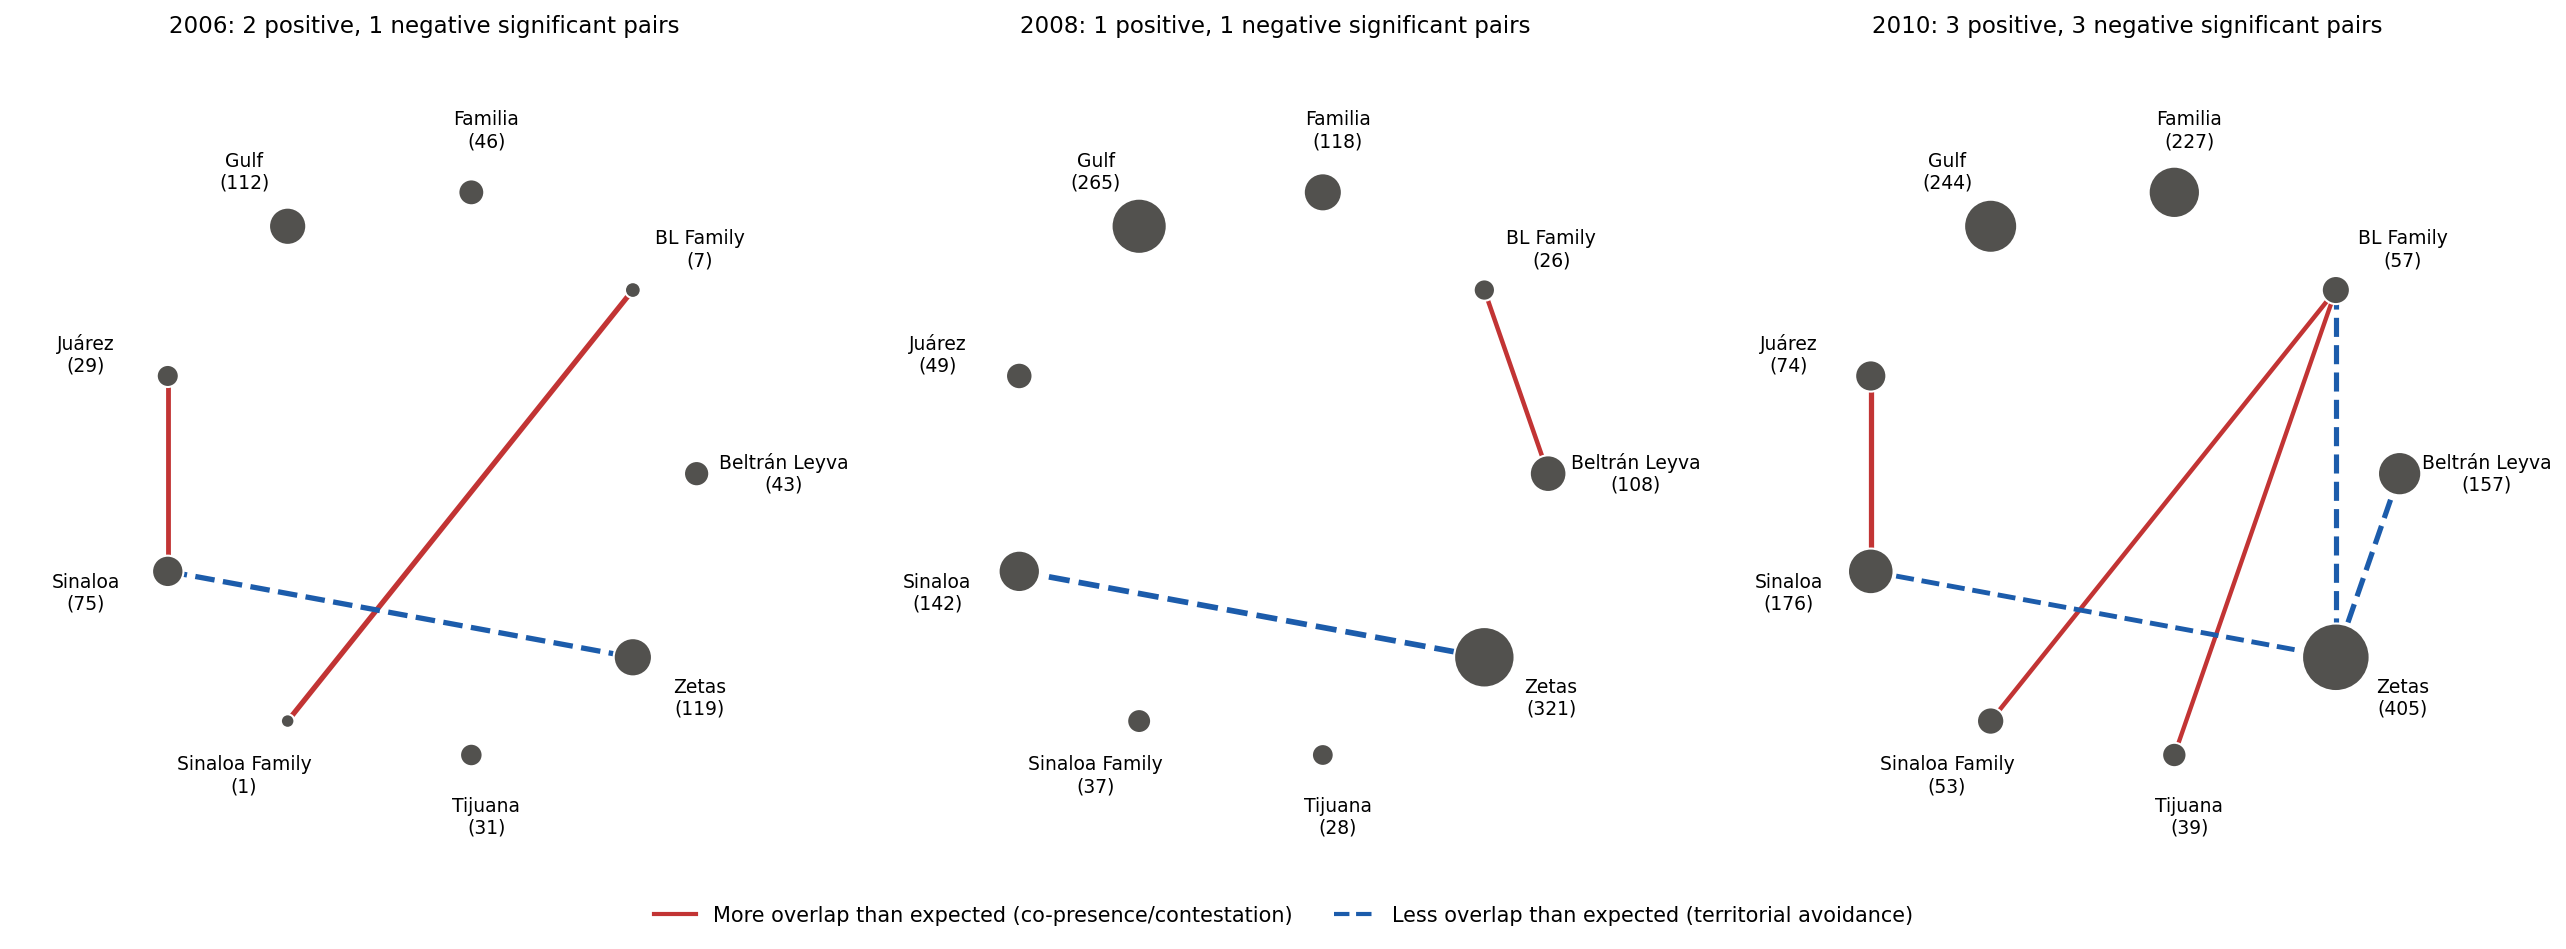

In [ ]:
# Significant pairs table & state-stratified cartel backbone
pair_rows = []
for year in focus_years:
    for a_index, a in enumerate(organization_columns):
        for b in organization_columns[a_index + 1:]:
            pair_rows.append({
                "year": year,
                "pair": f"{display_names[a]} – {display_names[b]}",
                "shared_municipalities": int(overlap_observed[year][organization_columns.index(a), organization_columns.index(b)]),
                "z_degree_null": overlap_z[(year, "degree")].loc[a, b],
                "z_state_null": overlap_z[(year, "state")].loc[a, b],
            })
pair_table = pd.DataFrame(pair_rows)
pair_table["significant_after_state_control"] = pair_table["z_state_null"].abs() >= critical_z
pair_wide = pair_table.pivot(index="pair", columns="year", values="z_state_null")
significant_pairs = pair_wide[(pair_wide.abs() >= critical_z).any(axis=1)]
print("State-stratified z-scores for cartel pairs significant in at least one focus year:")
display(significant_pairs.round(1).sort_values(focus_years[-1], ascending=False))

fig, axes = plt.subplots(1, len(focus_years), figsize=(17, 6), constrained_layout=True)
backbone_positions = nx.circular_layout(organization_columns)
for ax, year in zip(axes, focus_years):
    z = overlap_z[(year, "state")]
    degrees = active_by_year[year][organization_columns].sum()
    backbone = nx.Graph()
    backbone.add_nodes_from(organization_columns)
    for a_index, a in enumerate(organization_columns):
        for b in organization_columns[a_index + 1:]:
            if abs(z.loc[a, b]) >= critical_z:
                backbone.add_edge(a, b, z=z.loc[a, b])
    positive = [(a, b) for a, b, w in backbone.edges(data="z") if w > 0]
    negative = [(a, b) for a, b, w in backbone.edges(data="z") if w < 0]
    nx.draw_networkx_edges(backbone, backbone_positions, edgelist=positive, ax=ax, edge_color="#c23434",
                           width=[0.6 * abs(backbone.edges[e]["z"]) for e in positive])
    nx.draw_networkx_edges(backbone, backbone_positions, edgelist=negative, ax=ax, edge_color="#1c5cab",
                           style="dashed", width=[0.6 * abs(backbone.edges[e]["z"]) for e in negative])
    nx.draw_networkx_nodes(backbone, backbone_positions, ax=ax, node_color="#52514e", edgecolors="white",
                           node_size=[40 + 2.5 * degrees[n] for n in organization_columns])
    for node, (x, y) in backbone_positions.items():
        ax.text(x * 1.32, y * 1.22, f"{display_names[node]}\n({degrees[node]})", ha="center", va="center", fontsize=9)
    ax.set_title(f"{year}: {len(positive)} positive, {len(negative)} negative significant pairs", fontsize=11)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.axis("off")
fig.legend(
    handles=[
        Line2D([], [], color="#c23434", lw=2, label="More overlap than expected (co-presence/contestation)"),
        Line2D([], [], color="#1c5cab", lw=2, ls="--", label="Less overlap than expected (territorial avoidance)"),
    ],
    loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04),
)
show_figure(fig)

# Compute annual state-stratified z-scores for 1990–2009 to use as leak-free predictors at t -> t+1.
feature_z = norm.isf(0.025)
rival_z = {}
for year in range(min(years), max(years)):
    if year in focus_years:
        rival_z[year] = overlap_z[(year, "state")]
    else:
        rival_z[year], _ = overlap_zscores(active_records(year), True, seed=1000 + year)

# Also compute z-scores including 'Otros' strictly for the sensitivity check.
rival_z_all = {
    year: overlap_zscores(active_records(year, all_organization_columns), True, seed=2000 + year, org_cols=all_organization_columns)[0]
    for year in range(min(years), max(years))
}

## 3. Temporal Link Prediction: Emergence of New Connections (H1 & H2)

### 3.1 H1: Within-State Path Dependence

For adjacent years $t 	o t+1$ (2001–2010), we compare new link-formation rates among absent cartel–municipality pairs depending on whether the focal cartel is already active in **another municipality in the same state** at $t$, reporting 95% state-block bootstrap confidence intervals.

,candidates,new_associations,rate_same_state,rate_other_states,rate_ratio,ratio_ci_low,ratio_ci_high,share_of_new_in_present_state
analysis,,,,,,,,
Main (9 cartels),170130,3164,0.0341,0.0065,5.2680,3.4589,7.7533,0.8044
Sensitivity: Include Otros,187211,3271,0.0326,0.0062,5.2219,3.4450,7.6037,0.7946


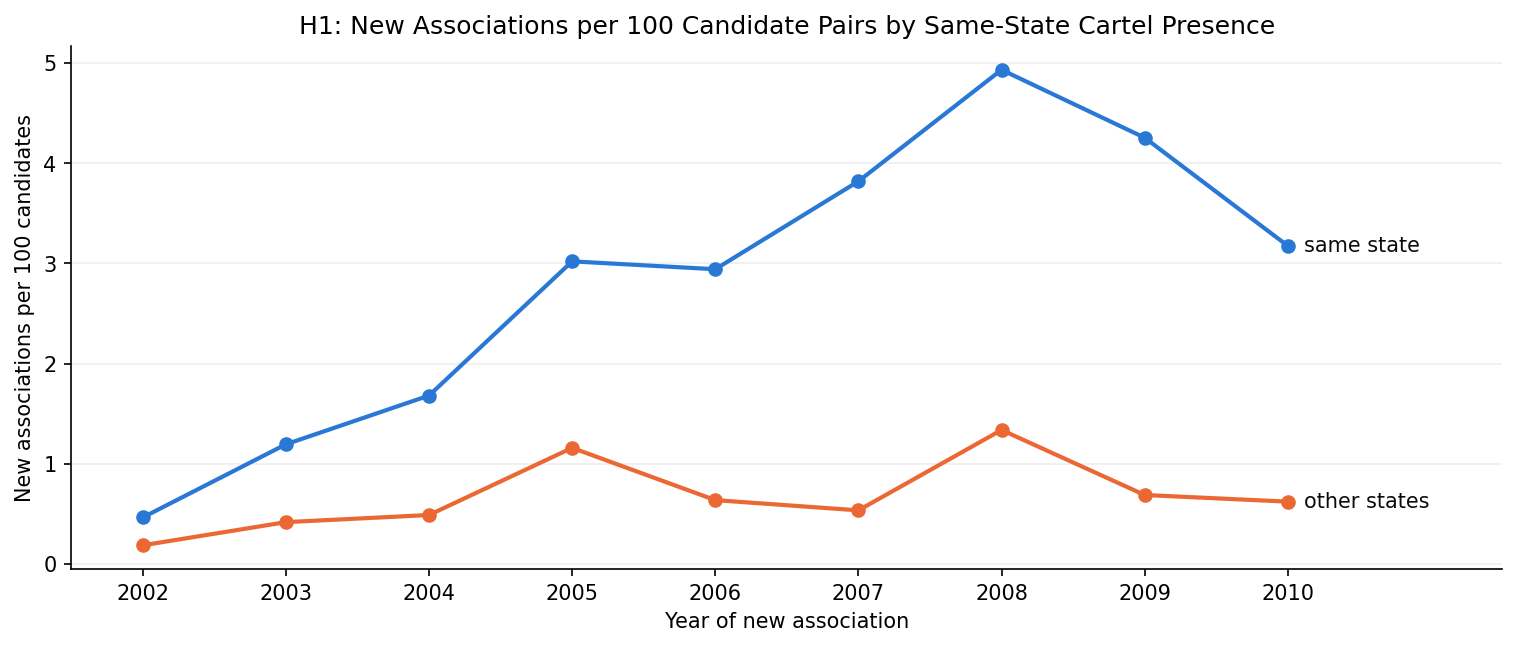

In [ ]:
def expansion_candidates(org_cols=organization_columns):
    frames = []
    for year in range(2001, 2010):
        before = data[data["Year"] == year].set_index("Code")
        after = data[data["Year"] == year + 1].set_index("Code")
        shared = before.index.intersection(after.index)
        before, after = before.loc[shared], after.loc[shared]
        for organization in org_cols:
            if before[organization].sum() == 0:
                continue
            present_states = set(before.loc[before[organization] == 1, "State"])
            candidates = before[organization] == 0
            frames.append(pd.DataFrame({
                "year": year + 1,
                "organization": organization,
                "state": before.loc[candidates, "State"].to_numpy(),
                "in_present_state": before.loc[candidates, "State"].isin(present_states).to_numpy(),
                "new": (after.loc[candidates, organization] == 1).to_numpy(),
            }))
    return pd.concat(frames, ignore_index=True)

def rate_ratio(candidates):
    rates = candidates.groupby("in_present_state")["new"].mean()
    return rates.get(True, np.nan) / rates.get(False, np.nan)

def state_bootstrap_interval(candidates, samples=1000, seed=0):
    rng = np.random.default_rng(seed)
    by_state = {state: group for state, group in candidates.groupby("state")}
    states = list(by_state)
    ratios = [rate_ratio(pd.concat([by_state[s] for s in rng.choice(states, len(states))])) for _ in range(samples)]
    return np.nanpercentile(ratios, [2.5, 97.5])

expansion_rows = []
for label, cols in [("Main (9 cartels)", organization_columns), ("Sensitivity: Include Otros", all_organization_columns)]:
    candidates = expansion_candidates(cols)
    low, high = state_bootstrap_interval(candidates)
    grouped = candidates.groupby("in_present_state")["new"]
    expansion_rows.append({
        "analysis": label,
        "candidates": len(candidates),
        "new_associations": int(candidates["new"].sum()),
        "rate_same_state": grouped.mean()[True],
        "rate_other_states": grouped.mean()[False],
        "rate_ratio": rate_ratio(candidates),
        "ratio_ci_low": low,
        "ratio_ci_high": high,
        "share_of_new_in_present_state": candidates.loc[candidates["new"], "in_present_state"].mean(),
    })
    if label.startswith("Main"):
        expansion_main = candidates

display(pd.DataFrame(expansion_rows).set_index("analysis").round(4))

expansion_by_year = expansion_main.groupby(["year", "in_present_state"])["new"].mean().unstack()
expansion_by_year.columns = ["other states", "same state"]
expansion_by_year["rate ratio"] = expansion_by_year["same state"] / expansion_by_year["other states"]

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
for column, color in [("same state", "#2a78d6"), ("other states", "#eb6834")]:
    ax.plot(expansion_by_year.index, 100 * expansion_by_year[column], color=color, lw=2, marker="o", ms=6)
    last = expansion_by_year.index[-1]
    ax.annotate(column, (last, 100 * expansion_by_year.loc[last, column]), xytext=(8, 0),
                textcoords="offset points", va="center", color="#0b0b0b")
ax.set(
    title="H1: New Associations per 100 Candidate Pairs by Same-State Cartel Presence",
    xlabel="Year of new association",
    ylabel="New associations per 100 candidates",
)
ax.set_xticks(expansion_by_year.index)
ax.set_xlim(expansion_by_year.index[0] - 0.5, expansion_by_year.index[-1] + 1.5)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 3.2 Leak-Free Feature Engineering (Historical, Structural & Territorial Features)

For every absent cartel–municipality pair at year $t$ (among municipalities observed at both $t$ and $t+1$, and cartels already active somewhere by $t$), we compute predictors strictly from information available at or before year $t$:
- **Historical features:** `previous_association` (whether the pair was linked prior to $t$) and `years_since_previous`.
- **Bipartite structural features:** `log_municipality_degree`, `log_organization_degree`, `log_three_step_paths` (number of length-3 bipartite walks connecting the municipality and cartel at $t$), and year-over-year degree changes.
- **Territorial & rivalry context features:** `other_organizations` in the municipality, `avoider_present` ($z \le -1.96$), `overlapper_present` ($z \ge 1.96$), `mean_rival_z`, `organization_in_state`, and `log_organization_state_count`.

In [ ]:
municipality_codes = sorted(data["Code"].unique())
code_index = {value: i for i, value in enumerate(municipality_codes)}
state_by_code = data.drop_duplicates("Code").set_index("Code")["State"].to_dict()

def build_matrices(org_cols):
    mats, rec_codes = {}, {}
    for year, rows in data.groupby("Year"):
        matrix = np.zeros((len(municipality_codes), len(org_cols)), dtype=np.int32)
        indexes = rows["Code"].map(code_index).to_numpy()
        matrix[indexes] = rows[org_cols].to_numpy(dtype=np.int32)
        mats[int(year)] = matrix
        rec_codes[int(year)] = set(rows["Code"])
    return mats, rec_codes

matrices, recorded_codes = build_matrices(organization_columns)
matrices_all, _ = build_matrices(all_organization_columns)

def add_territory_features(frame, mats, z_by_year, org_cols):
    org_idx = {value: i for i, value in enumerate(org_cols)}
    parts = []
    for feature_year, part in frame.groupby(frame["prediction_year"] - 1):
        current = mats[feature_year]
        z = z_by_year[feature_year].to_numpy()
        m = part["municipality"].map(code_index).to_numpy()
        c = part["organization"].map(org_idx).to_numpy()
        others = current[m].astype(float)
        others[np.arange(len(m)), c] = 0
        z_with_focal = z[:, c].T
        n_others = others.sum(axis=1)
        state_counts = data[data["Year"] == feature_year].groupby("State")[org_cols].sum()
        in_state = state_counts.reindex(part["state"]).to_numpy()[np.arange(len(m)), c] - current[m, c]
        part = part.copy()
        part["other_organizations"] = n_others
        part["mean_rival_z"] = np.where(n_others > 0, (others * z_with_focal).sum(axis=1) / np.maximum(n_others, 1), 0.0)
        part["avoider_present"] = ((others * (z_with_focal <= -feature_z)).sum(axis=1) > 0).astype(int)
        part["overlapper_present"] = ((others * (z_with_focal >= feature_z)).sum(axis=1) > 0).astype(int)
        part["organization_in_state"] = (in_state > 0).astype(int)
        part["log_organization_state_count"] = np.log1p(in_state)
        parts.append(part)
    return pd.concat(parts).sort_index()

def rival_context(frame):
    return pd.Categorical(
        np.select(
            [frame["other_organizations"] == 0, frame["avoider_present"] == 1, frame["overlapper_present"] == 1],
            ["no other organization", "avoiding rival present", "overlapping organization present"],
            "only neutral organizations",
        ),
        categories=[
            "no other organization",
            "only neutral organizations",
            "overlapping organization present",
            "avoiding rival present",
        ],
    )

def build_candidate_dataset(mats, z_by_year, org_cols):
    last_seen = np.full_like(mats[min(years)], -1)
    previous_matrix = np.zeros_like(last_seen)
    frames, elig_records = [], []
    for year in years[:-1]:
        current, following = mats[year], mats[year + 1]
        last_seen[current == 1] = year
        eligible_orgs = (last_seen >= 0).any(axis=0)
        shared_indexes = np.array([code_index[c] for c in sorted(recorded_codes[year] & recorded_codes[year + 1])])
        candidate_mask = (current[shared_indexes] == 0) & eligible_orgs[None, :]
        local_m, org = np.where(candidate_mask)
        municipality = shared_indexes[local_m]
        three_paths = current @ (current.T @ current)
        m_deg, o_deg = current.sum(axis=1), current.sum(axis=0)
        prior_m_deg, prior_o_deg = previous_matrix.sum(axis=1), previous_matrix.sum(axis=0)
        had_previous = last_seen[municipality, org] >= 0
        frame = pd.DataFrame({
            "prediction_year": year + 1,
            "municipality": [municipality_codes[i] for i in municipality],
            "organization": [org_cols[i] for i in org],
            "new_link": following[municipality, org],
            "previous_association": had_previous.astype(int),
            "years_since_previous": np.where(had_previous, year - last_seen[municipality, org], 0),
            "municipality_degree": m_deg[municipality],
            "organization_degree": o_deg[org],
            "three_step_paths": three_paths[municipality, org],
            "municipality_degree_change": m_deg[municipality] - prior_m_deg[municipality],
            "organization_degree_change": o_deg[org] - prior_o_deg[org],
        })
        frame["state"] = frame["municipality"].map(state_by_code)
        for feat in ["municipality_degree", "organization_degree", "three_step_paths"]:
            frame[f"log_{feat}"] = np.log1p(frame[feat])
        frames.append(frame)
        elig_records.append({
            "prediction_year": year + 1,
            "eligible_pairs": len(frame),
            "new_links": int(frame["new_link"].sum()),
        })
        previous_matrix = current
    full = pd.concat(frames, ignore_index=True)
    full = add_territory_features(full, mats, z_by_year, org_cols)
    full["rival_context"] = rival_context(full)
    return full, pd.DataFrame(elig_records).set_index("prediction_year")

research_data, eligibility_summary = build_candidate_dataset(matrices, rival_z, organization_columns)
research_data_all, _ = build_candidate_dataset(matrices_all, rival_z_all, all_organization_columns)

territory_features = [
    "mean_rival_z", "avoider_present", "overlapper_present",
    "organization_in_state", "log_organization_state_count",
]
assert not research_data[territory_features].isna().any().any()
assert not research_data.duplicated(["prediction_year", "municipality", "organization"]).any()

display(eligibility_summary.loc[2000:])
display(research_data.groupby("rival_context", observed=True)["new_link"].agg(["size", "sum", "mean"]))

,eligible_pairs,new_links
prediction_year,,
2000,17168,53
2001,17139,49
2002,19584,42
2003,19600,89
2004,19549,131
2005,19489,305
2006,19291,343
2007,21650,452
2008,21455,722


,size,sum,mean
rival_context,,,
no other organization,298478,1597,0.005350
only neutral organizations,11238,851,0.075725
overlapping organization present,2644,465,0.175870
avoiding rival present,4873,558,0.114509


### 3.3 Chronological Link Prediction & Evaluation

We evaluate predictive models using strictly chronological expanding-window splits (training on outcomes from $2000$ to $t-1$ to predict year $t$):
- **Development period:** 2007 and 2008
- **Final held-out evaluation period:** 2009 and 2010

Models are ranked by **Average Precision (AP)**, **Precision@100**, and **Recall@100**, comparing simple structural heuristics (`Constant baseline`, `Municipality degree`, `Degree product`) against regularized logistic models (`History`, `History + structure`, `History + territory`). Paired state-block bootstrap intervals quantify AP gains over the `History` model.

year,2007,2008,2009,2010
model,,,,
Constant baseline,0.0209,0.0337,0.0290,0.0234
Degree product,0.1344,0.1441,0.1611,0.1305
History + structure,0.2111,0.2272,0.2265,0.2418
History + territory,0.2510,0.2136,0.2839,0.2899
History model,0.1724,0.1827,0.1969,0.2559
Municipality degree,0.0683,0.0943,0.0955,0.0882


,scenario,year,split,model,candidates,positives,formation_rate,average_precision,precision_at_100,recall_at_100
0,Main (9 cartels),2007,Development,Constant baseline,21650,452,0.0209,0.0209,0.0209,0.0046
1,Main (9 cartels),2007,Development,Municipality degree,21650,452,0.0209,0.0683,0.1800,0.0398
2,Main (9 cartels),2007,Development,Degree product,21650,452,0.0209,0.1344,0.3200,0.0708
3,Main (9 cartels),2007,Development,History model,21650,452,0.0209,0.1724,0.4200,0.0929
4,Main (9 cartels),2007,Development,History + structure,21650,452,0.0209,0.2111,0.3700,0.0819
...,...,...,...,...,...,...,...,...,...,...
67,Sensitivity: Include Otros,2010,Final,Municipality degree,23191,514,0.0222,0.0960,0.2400,0.0467
68,Sensitivity: Include Otros,2010,Final,Degree product,23191,514,0.0222,0.1309,0.1700,0.0331
69,Sensitivity: Include Otros,2010,Final,History model,23191,514,0.0222,0.2481,0.4700,0.0914
70,Sensitivity: Include Otros,2010,Final,History + structure,23191,514,0.0222,0.2400,0.3300,0.0642


AP_gain_over_history  state_bootstrap_95_lower  \
year model                                                                 
2009 History + structure                0.0297                   -0.0113   
     History + territory                0.0870                    0.0477   
2010 History + structure               -0.0141                   -0.0631   
     History + territory                0.0340                   -0.0027   

                          state_bootstrap_95_upper  
year model                                          
2009 History + structure                    0.0687  
     History + territory                    0.1254  
2010 History + structure                    0.0238  
     History + territory                    0.0655

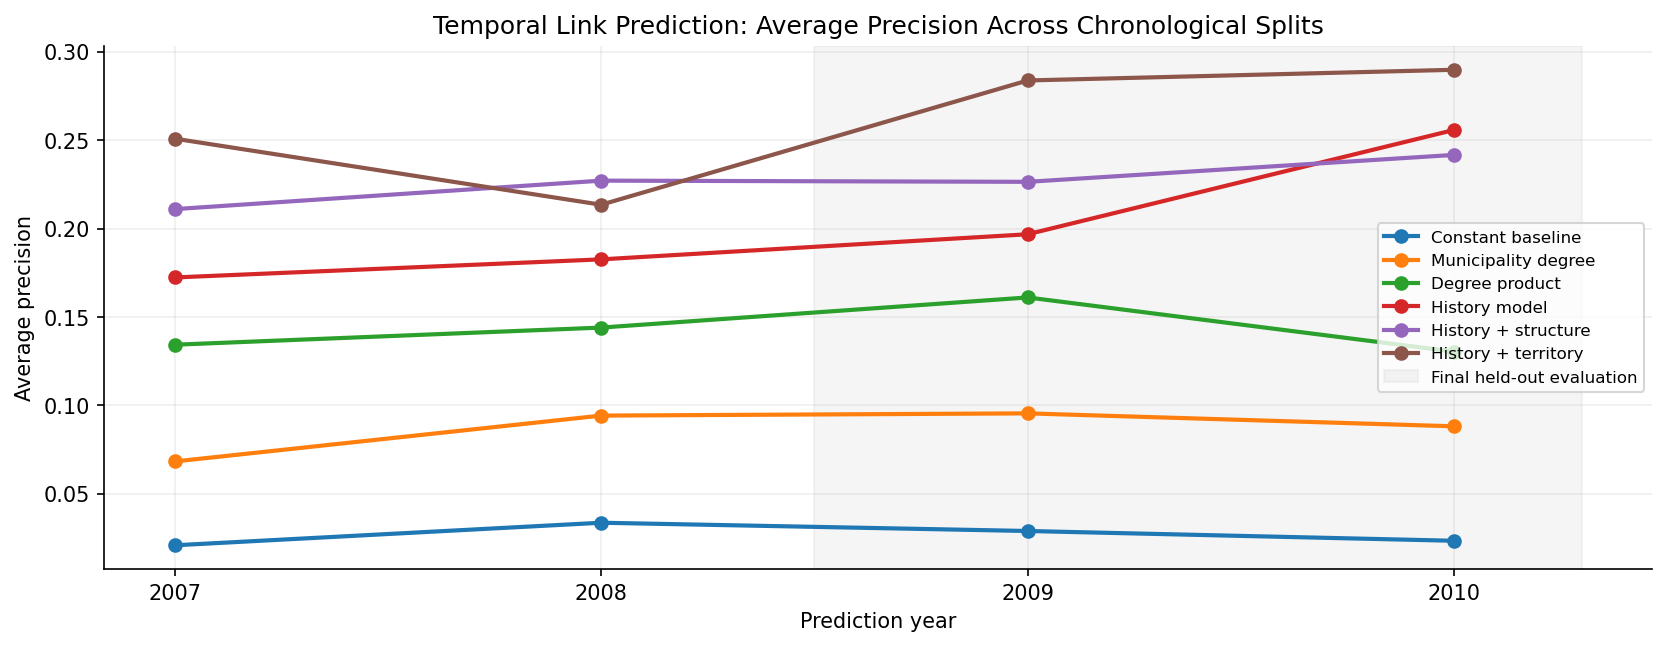

In [ ]:
history_features = ["previous_association", "years_since_previous"]
network_features = [
    "log_municipality_degree", "log_organization_degree", "log_three_step_paths",
    "municipality_degree_change", "organization_degree_change",
]

def make_link_model(numeric_features):
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("organization", OneHotEncoder(handle_unknown="ignore"), ["organization"]),
    ])
    return make_pipeline(preprocessing, LogisticRegression(C=1, max_iter=1000, solver="lbfgs"))

def ranking_metrics(labels, scores, k=100):
    labels, scores = np.asarray(labels), np.asarray(scores)
    selected = np.argsort(-scores, kind="stable")[:min(k, len(labels))]
    positives = int(labels.sum())
    return {
        "average_precision": average_precision_score(labels, scores) if positives else np.nan,
        "precision_at_100": labels[selected].mean() if len(selected) else np.nan,
        "recall_at_100": labels[selected].sum() / positives if positives else np.nan,
    }

scenario_datasets = {
    "Main (9 cartels)": research_data,
    "First observed only": research_data[research_data["previous_association"] == 0],
    "Sensitivity: Include Otros": research_data_all,
}

evaluation_records, heldout_predictions = [], []
for scenario, scenario_data in scenario_datasets.items():
    for target_year in [2007, 2008, 2009, 2010]:
        train = scenario_data[(scenario_data["prediction_year"] >= 2000) & (scenario_data["prediction_year"] < target_year)]
        test = scenario_data[scenario_data["prediction_year"] == target_year].sort_values(["municipality", "organization"]).copy()
        assert train["prediction_year"].max() < test["prediction_year"].min()
        assert train["new_link"].nunique() == 2 and len(test) > 0
        scores = {
            "Constant baseline": np.zeros(len(test)),
            "Municipality degree": test["municipality_degree"].to_numpy(),
            "Degree product": (test["municipality_degree"] * test["organization_degree"]).to_numpy(),
        }
        for label, features in [
            ("History model", history_features),
            ("History + structure", history_features + network_features),
            ("History + territory", history_features + territory_features),
        ]:
            fitted = make_link_model(features).fit(train, train["new_link"])
            scores[label] = fitted.predict_proba(test)[:, 1]
        for label, predictions in scores.items():
            metrics = ranking_metrics(test["new_link"], predictions)
            if label == "Constant baseline":
                metrics["precision_at_100"] = test["new_link"].mean()
                metrics["recall_at_100"] = min(100, len(test)) / len(test)
            evaluation_records.append({
                "scenario": scenario,
                "year": target_year,
                "split": "Development" if target_year < 2009 else "Final",
                "model": label,
                "candidates": len(test),
                "positives": int(test["new_link"].sum()),
                "formation_rate": test["new_link"].mean(),
                **metrics,
            })
        if scenario == "Main (9 cartels)" and target_year >= 2009:
            for label, predictions in scores.items():
                test[label] = predictions
            heldout_predictions.append(test)

evaluation_results = pd.DataFrame(evaluation_records)
final_predictions = pd.concat(heldout_predictions, ignore_index=True)

main_results = evaluation_results[evaluation_results["scenario"] == "Main (9 cartels)"]
display(main_results.pivot(index="model", columns="year", values="average_precision").round(4))
display(evaluation_results.round(4))

# Paired state-block bootstrap for AP gains over the History model in 2009–2010
rng = np.random.default_rng(42)
bootstrap_records = []
for target_year, test in final_predictions.groupby("prediction_year"):
    states = sorted(test["state"].unique())
    state_codes = pd.Categorical(test["state"], categories=states).codes
    differences = {"History + structure": [], "History + territory": []}
    for _ in range(200):
        multiplicity = np.bincount(rng.integers(0, len(states), len(states)), minlength=len(states))
        weights = multiplicity[state_codes]
        if np.dot(weights, test["new_link"]) == 0:
            continue
        history_ap = average_precision_score(test["new_link"], test["History model"], sample_weight=weights)
        for label in differences:
            differences[label].append(average_precision_score(test["new_link"], test[label], sample_weight=weights) - history_ap)
    for label, values in differences.items():
        point = average_precision_score(test["new_link"], test[label]) - average_precision_score(test["new_link"], test["History model"])
        low, high = np.quantile(values, [0.025, 0.975])
        bootstrap_records.append({
            "year": target_year,
            "model": label,
            "AP_gain_over_history": point,
            "state_bootstrap_95_lower": low,
            "state_bootstrap_95_upper": high,
        })
prediction_uncertainty = pd.DataFrame(bootstrap_records).set_index(["year", "model"])
display(prediction_uncertainty.round(4))

fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
for label, group in main_results.groupby("model", sort=False):
    ax.plot(group["year"], group["average_precision"], marker="o", lw=2, label=label)
ax.axvspan(2008.5, 2010.3, color="gray", alpha=0.08, label="Final held-out evaluation")
ax.set(
    title="Temporal Link Prediction: Average Precision Across Chronological Splits",
    xlabel="Prediction year",
    ylabel="Average precision",
    xticks=[2007, 2008, 2009, 2010],
)
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 3.4 Statistical Associations on Development Data (2000–2008)

To interpret the structural and territorial mechanisms associated with link emergence, we fit state-clustered Binomial GLMs (with cartel and year fixed effects) on the 2000–2008 development window and examine formation rates across rival contexts over 2000–2010.

In [ ]:
def grouped_rates(frame, outcome, group, samples=1000, seed=0):
    counts = frame.groupby(["state", group], observed=False)[outcome].agg(["sum", "size"]).unstack(fill_value=0)
    events, totals = counts["sum"].to_numpy(float), counts["size"].to_numpy(float)
    rng = np.random.default_rng(seed)
    weights = rng.multinomial(len(events), np.full(len(events), 1 / len(events)), size=samples)
    bootstrap = (weights @ events) / np.maximum(weights @ totals, 1)
    return pd.DataFrame({
        "pairs": totals.sum(axis=0).astype(int),
        "events": events.sum(axis=0).astype(int),
        "rate": events.sum(axis=0) / np.maximum(totals.sum(axis=0), 1),
        "ci_low": np.percentile(bootstrap, 2.5, axis=0),
        "ci_high": np.percentile(bootstrap, 97.5, axis=0),
    }, index=counts["sum"].columns)

def fit_territory_glm(frame, outcome, binary_terms, numeric_controls):
    frame = frame.copy()
    names = {}
    for column in numeric_controls:
        deviation = frame[column].std(ddof=0)
        if deviation > 0:
            frame[f"z_{column}"] = (frame[column] - frame[column].mean()) / deviation
            names[f"z_{column}"] = column
    terms = binary_terms + list(names)
    formula = f"{outcome} ~ " + " + ".join(terms) + " + C(organization) + C(prediction_year)"
    model = GLM.from_formula(formula, data=frame, family=Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": frame["state"]}, maxiter=100
    )
    assert model.converged, f"{outcome} GLM did not converge."
    intervals = model.conf_int()
    return model, pd.DataFrame({
        "feature": [names.get(term, term) for term in terms],
        "odds_ratio": np.exp(model.params[terms].to_numpy()),
        "95_lower": np.exp(intervals.loc[terms, 0].to_numpy()),
        "95_upper": np.exp(intervals.loc[terms, 1].to_numpy()),
        "p_value": model.pvalues[terms].to_numpy(),
    })

formation_window = research_data[research_data["prediction_year"].between(2000, 2010)]
formation_by_context = grouped_rates(formation_window, "new_link", "rival_context")
display(formation_by_context.round(4))

formation_binary = ["previous_association", "organization_in_state", "avoider_present", "overlapper_present"]
formation_controls = ["years_since_previous", "log_municipality_degree", "log_organization_degree"]
formation_glm, formation_effects = fit_territory_glm(
    research_data[research_data["prediction_year"].between(2000, 2008)],
    "new_link",
    formation_binary,
    formation_controls,
)
display(formation_effects.round(4))

,pairs,events,rate,ci_low,ci_high
rival_context,,,,,
no other organization,198951,1453,0.0073,0.0043,0.0120
only neutral organizations,10278,806,0.0784,0.0662,0.0919
overlapping organization present,2620,465,0.1775,0.1543,0.2036
avoiding rival present,4873,558,0.1145,0.0962,0.1342


,feature,odds_ratio,95_lower,95_upper,p_value
0,previous_association,10.0137,7.2059,13.9155,0.0000
1,organization_in_state,1.9919,1.3247,2.9952,0.0009
2,avoider_present,0.4771,0.3465,0.6569,0.0000
3,overlapper_present,1.2581,0.9594,1.6500,0.0969
4,years_since_previous,0.9875,0.9626,1.0131,0.3347
5,log_municipality_degree,1.5469,1.4181,1.6874,0.0000
6,log_organization_degree,1.7278,1.3421,2.2243,0.0000


## 4. Extensions & Robustness: Disappearance (H3) and Cartel Heterogeneity (H4)

### 4.1 H3: Disappearance of Existing Associations

To test whether rival presence displaces existing cartels, we mirror the formation design on cartel–municipality pairs **present** at year $t$ (in municipalities observed at both $t$ and $t+1$), modeling `disappeared = 1` when the association is absent at $t+1$.

,pairs,events,rate,ci_low,ci_high
rival_context,,,,,
no other organization,1260,642,0.5095,0.4653,0.5500
only neutral organizations,1023,471,0.4604,0.4118,0.5099
overlapping organization present,1451,550,0.3790,0.3331,0.4284
avoiding rival present,665,235,0.3534,0.3060,0.3981


,feature,odds_ratio,95_lower,95_upper,p_value
0,organization_in_state,0.7899,0.5481,1.1381,0.2056
1,avoider_present,1.1339,0.7997,1.6078,0.4805
2,overlapper_present,1.1081,0.8415,1.4593,0.4646
3,log_years_present,0.5923,0.5254,0.6677,0.0000
4,log_other_organizations,0.8320,0.7450,0.9291,0.0011
5,log_organization_degree,0.7416,0.5688,0.9668,0.0271


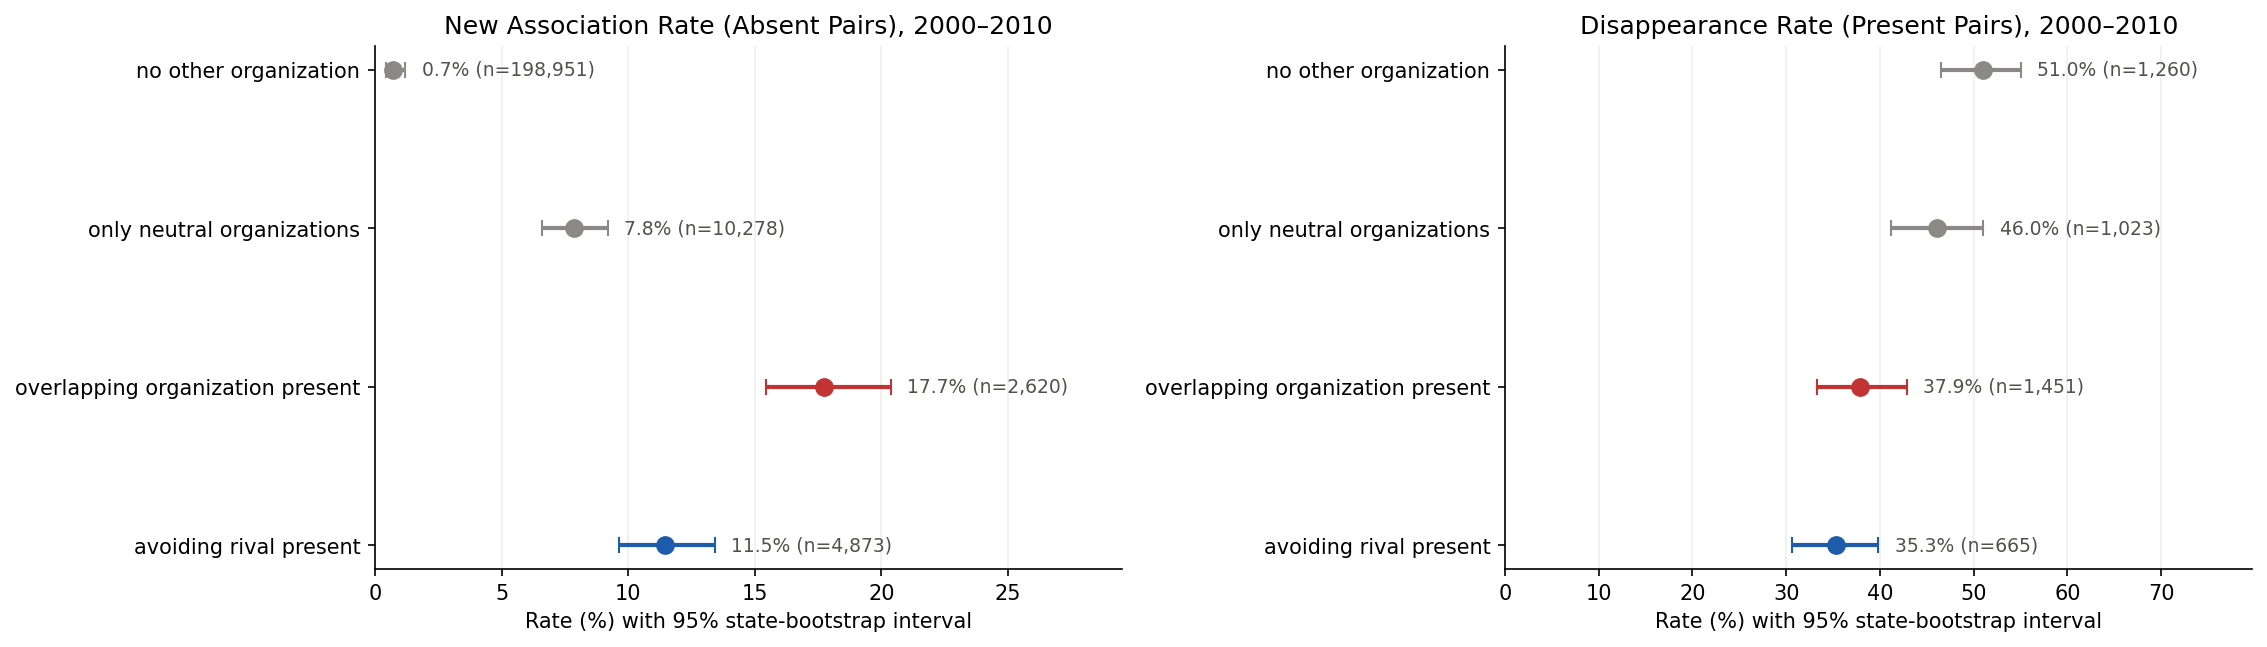

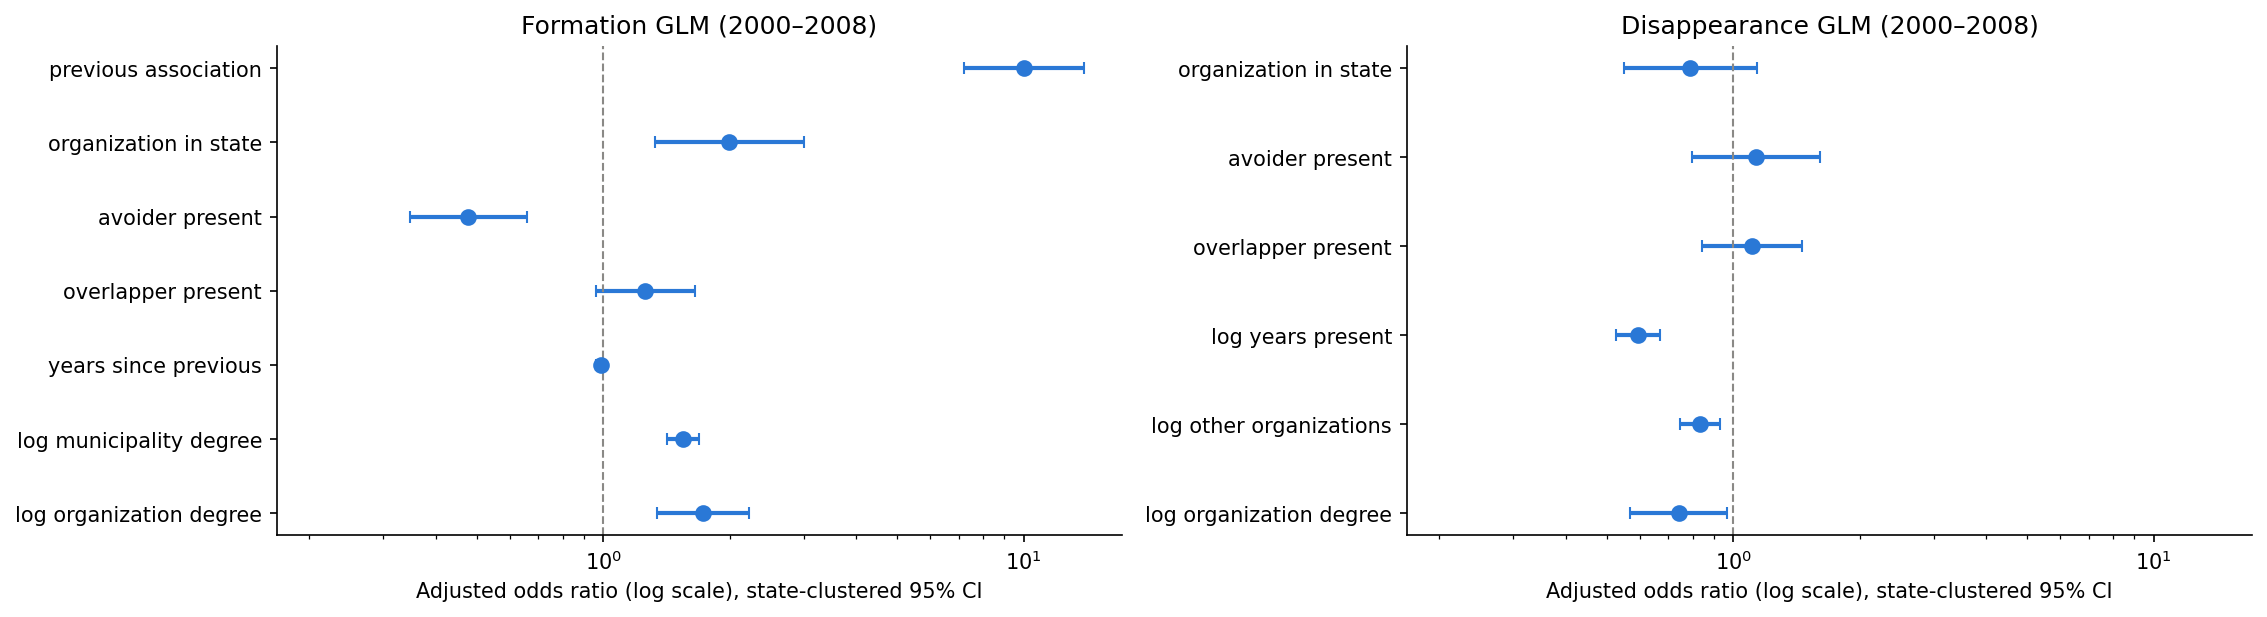

In [ ]:
def build_exit_dataset(mats, z_by_year, org_cols):
    exit_frames = []
    streak = np.zeros_like(mats[years[0]])
    for year in years[:-1]:
        current, following = mats[year], mats[year + 1]
        streak = np.where(current == 1, streak + 1, 0)
        shared_indexes = np.array([code_index[c] for c in sorted(recorded_codes[year] & recorded_codes[year + 1])])
        local_m, org = np.where(current[shared_indexes] == 1)
        if len(local_m) == 0:
            continue
        municipality = shared_indexes[local_m]
        exit_frames.append(pd.DataFrame({
            "prediction_year": year + 1,
            "municipality": [municipality_codes[i] for i in municipality],
            "organization": [org_cols[i] for i in org],
            "disappeared": 1 - following[municipality, org],
            "years_present": streak[municipality, org],
            "organization_degree": current.sum(axis=0)[org],
        }))
    exits = pd.concat(exit_frames, ignore_index=True)
    exits["state"] = exits["municipality"].map(state_by_code)
    exits = add_territory_features(exits, mats, z_by_year, org_cols)
    exits["rival_context"] = rival_context(exits)
    for feat in ["years_present", "organization_degree", "other_organizations"]:
        exits[f"log_{feat}"] = np.log1p(exits[feat])
    return exits

exit_data = build_exit_dataset(matrices, rival_z, organization_columns)
exit_data_all = build_exit_dataset(matrices_all, rival_z_all, all_organization_columns)

exit_window = exit_data[exit_data["prediction_year"].between(2000, 2010)]
exit_by_context = grouped_rates(exit_window, "disappeared", "rival_context")
display(exit_by_context.round(4))

exit_binary = ["organization_in_state", "avoider_present", "overlapper_present"]
exit_controls = ["log_years_present", "log_other_organizations", "log_organization_degree"]
exit_glm, exit_effects = fit_territory_glm(
    exit_data[exit_data["prediction_year"].between(2000, 2008)],
    "disappeared",
    exit_binary,
    exit_controls,
)
display(exit_effects.round(4))

# Side-by-side comparison of Formation vs. Disappearance rates and adjusted odds ratios
context_colors = {
    "no other organization": "#8a8986",
    "only neutral organizations": "#8a8986",
    "overlapping organization present": "#c23434",
    "avoiding rival present": "#1c5cab",
}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), constrained_layout=True)
for ax, (table, title) in zip(axes, [
    (formation_by_context, "New Association Rate (Absent Pairs)"),
    (exit_by_context, "Disappearance Rate (Present Pairs)"),
]):
    positions = np.arange(len(table))[::-1]
    for y, (context, row) in zip(positions, table.iterrows()):
        ax.errorbar(
            100 * row["rate"], y,
            xerr=[[100 * (row["rate"] - row["ci_low"])], [100 * (row["ci_high"] - row["rate"])]],
            fmt="o", ms=8, color=context_colors[context], capsize=4, lw=2,
        )
        ax.annotate(
            f"{100 * row['rate']:.1f}% (n={int(row['pairs']):,})",
            (100 * row["ci_high"], y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e",
        )
    ax.set_yticks(positions, table.index)
    ax.set_xlim(0, 100 * table["ci_high"].max() * 1.45)
    ax.set(title=f"{title}, 2000–2010", xlabel="Rate (%) with 95% state-bootstrap interval")
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True, sharex=True)
for ax, (effects, title) in zip(axes, [
    (formation_effects, "Formation GLM (2000–2008)"),
    (exit_effects, "Disappearance GLM (2000–2008)"),
]):
    positions = np.arange(len(effects))[::-1]
    ax.errorbar(
        effects["odds_ratio"], positions,
        xerr=[effects["odds_ratio"] - effects["95_lower"], effects["95_upper"] - effects["odds_ratio"]],
        fmt="o", ms=7, color="#2a78d6", capsize=3, lw=2,
    )
    ax.axvline(1, color="#8a8986", linestyle="--", lw=1)
    ax.set_yticks(positions, effects["feature"].str.replace("_", " "))
    ax.set(title=title, xscale="log", xlabel="Adjusted odds ratio (log scale), state-clustered 95% CI")
    ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

### 4.2 H4: Cartel-Level Heterogeneity & Sensitivity Checks

We disaggregate expansion and disappearance patterns across the 9 cartels (flagging cartels with fewer than 30 new associations) and verify that our GLM estimates remain stable when including `Otros` or restricting link formation to first-observed events.

In [ ]:
h4_rows = []
for organization in organization_columns:
    formed = formation_window[formation_window["organization"] == organization]
    exits = exit_window[exit_window["organization"] == organization]
    new = formed[formed["new_link"] == 1]
    in_state_rate = formed.loc[formed["organization_in_state"] == 1, "new_link"].mean()
    out_state_rate = formed.loc[formed["organization_in_state"] == 0, "new_link"].mean()
    h4_rows.append({
        "cartel": display_names[organization],
        "new_associations": len(new),
        "same_state_ratio": in_state_rate / out_state_rate if out_state_rate > 0 else np.nan,
        "share_new_into_occupied": (new["other_organizations"] > 0).mean() if len(new) else np.nan,
        "share_new_with_avoider": new["avoider_present"].mean() if len(new) else np.nan,
        "present_pair_years": len(exits),
        "disappearance_rate": exits["disappeared"].mean() if len(exits) else np.nan,
        "disappearance_rate_with_avoider": exits.loc[exits["avoider_present"] == 1, "disappeared"].mean(),
        "few_events": len(new) < 30,
    })
organization_patterns = pd.DataFrame(h4_rows).set_index("cartel").sort_values("new_associations", ascending=False)
display(organization_patterns.round(3))

# Robustness table across Main (9 cartels), Include Otros, and First-observed-only subsets
robust_rows = []
scenarios = [
    ("Formation", "Main (9 cartels)", research_data, "new_link", formation_binary, formation_controls),
    ("Formation", "Include Otros", research_data_all, "new_link", formation_binary, formation_controls),
    (
        "Formation",
        "First observed only",
        research_data[research_data["previous_association"] == 0],
        "new_link",
        [t for t in formation_binary if t != "previous_association"],
        [c for c in formation_controls if c != "years_since_previous"],
    ),
    ("Disappearance", "Main (9 cartels)", exit_data, "disappeared", exit_binary, exit_controls),
    ("Disappearance", "Include Otros", exit_data_all, "disappeared", exit_binary, exit_controls),
]
for outcome_name, scenario, frame, outcome, binary, controls in scenarios:
    _, effects = fit_territory_glm(frame[frame["prediction_year"].between(2000, 2008)], outcome, binary, controls)
    for _, row in effects[effects["feature"].isin(["organization_in_state", "avoider_present", "overlapper_present"])].iterrows():
        robust_rows.append({
            "outcome": outcome_name,
            "scenario": scenario,
            "feature": row["feature"],
            "odds_ratio": row["odds_ratio"],
            "95_lower": row["95_lower"],
            "95_upper": row["95_upper"],
        })
robustness = pd.DataFrame(robust_rows)
display(robustness.pivot_table(index=["outcome", "scenario"], columns="feature", values="odds_ratio").round(2))

,new_associations,same_state_ratio,share_new_into_occupied,share_new_with_avoider,present_pair_years,disappearance_rate,disappearance_rate_with_avoider,few_events
cartel,,,,,,,,
Zetas,823,8.363,0.433,0.194,1161,0.364,0.266,False
Gulf,675,3.967,0.464,0.138,1026,0.424,0.355,False
Sinaloa,474,3.749,0.599,0.333,651,0.461,0.414,False
Familia,374,10.090,0.602,0.051,416,0.353,0.750,False
Beltrán Leyva,363,4.347,0.683,0.198,431,0.501,0.375,False
Juárez,222,3.187,0.626,0.171,293,0.543,0.393,False
Tijuana,157,3.451,0.599,0.051,226,0.562,0.385,False
Sinaloa Family,101,5.911,0.881,0.000,98,0.490,NaN,False
BL Family,93,6.334,0.871,0.108,97,0.443,0.474,False


feature                            avoider_present  organization_in_state  \
outcome       scenario                                                      
Disappearance Include Otros                   1.02                   0.73   
              Main (9 cartels)                1.13                   0.79   
Formation     First observed only             0.59                   2.04   
              Include Otros                   0.47                   1.96   
              Main (9 cartels)                0.48                   1.99   

feature                            overlapper_present  
outcome       scenario                                 
Disappearance Include Otros                      1.03  
              Main (9 cartels)                   1.11  
Formation     First observed only                1.64  
              Include Otros                      1.17  
              Main (9 cartels)                   1.26

## 5. Mesoscale Structure & Network Intervention Simulation

### 5.1 Municipality Backbone & Louvain Communities

Projecting the bipartite graph onto municipalities connects municipalities that share at least one cartel. To filter out dense "hairball" artifacts from large cartels, we apply the **Noise-Corrected (NC) backbone** (Coscia & Neffke, 2017) and **Disparity filter** (Serrano et al., 2009), detect Louvain communities, and measure alignment with administrative state boundaries via Normalized Mutual Information (NMI) against 1,000 random state permutations.

In [ ]:
def municipality_projection(records, org_cols=organization_columns):
    matrix = records[org_cols].to_numpy()
    weights = matrix @ matrix.T
    np.fill_diagonal(weights, 0)
    return weights.astype(float)

def noise_corrected_backbone(weights, delta=1.64):
    n_i = weights.sum(axis=1)
    total = weights.sum()
    if total <= 1:
        return np.zeros_like(weights, dtype=bool)
    i, j = np.nonzero(np.triu(weights, 1))
    n_ij, ni, nj = weights[i, j], n_i[i], n_i[j]
    kappa = total / (ni * nj)
    score = (kappa * n_ij - 1) / (kappa * n_ij + 1)
    prior_mean = ni * nj / total ** 2
    prior_var = (ni * nj * (total - ni) * (total - nj)) / (total ** 4 * (total - 1))
    valid = prior_var > 0
    keep = np.zeros_like(weights, dtype=bool)
    if not np.any(valid):
        return keep
    i, j, n_ij, ni, nj, kappa, score, prior_mean, prior_var = (
        i[valid], j[valid], n_ij[valid], ni[valid], nj[valid],
        kappa[valid], score[valid], prior_mean[valid], prior_var[valid],
    )
    alpha_prior = (prior_mean ** 2 / prior_var) * (1 - prior_mean) - prior_mean
    beta_prior = (prior_mean / prior_var) * (1 - prior_mean ** 2) - (1 - prior_mean)
    posterior = (alpha_prior + n_ij) / (alpha_prior + n_ij + total - n_ij + beta_prior)
    variance_nij = posterior * (1 - posterior) * total
    d = 1 / (ni * nj) - total * (ni + nj) / (ni * nj) ** 2
    variance_score = variance_nij * (2 * (kappa + n_ij * d) / (kappa * n_ij + 1) ** 2) ** 2
    keep[i, j] = score - delta * np.sqrt(np.maximum(variance_score, 0.0)) > 0
    return keep | keep.T

def disparity_backbone(weights, alpha=0.05):
    strength = weights.sum(axis=1, keepdims=True)
    degree = (weights > 0).sum(axis=1, keepdims=True)
    share = np.divide(weights, strength, out=np.zeros_like(weights), where=strength > 0)
    with np.errstate(invalid="ignore"):
        significance = (1 - share) ** (degree - 1)
    kept_by_node = (weights > 0) & (degree > 1) & (significance < alpha)
    return kept_by_node | kept_by_node.T

def graph_from_matrix(records, weights, keep):
    graph = nx.Graph()
    codes = records["Code"].to_numpy()
    graph.add_nodes_from((code, {"state": state}) for code, state in zip(codes, records["State"]))
    i, j = np.nonzero(np.triu(keep, 1))
    graph.add_weighted_edges_from(zip(codes[i], codes[j], weights[i, j]))
    return graph

projection_rows, municipality_backbones, community_rows = [], {}, []
for year in focus_years:
    records = active_by_year[year]
    weights = municipality_projection(records)
    naive = weights > 0
    nc = noise_corrected_backbone(weights)
    disparity = disparity_backbone(weights)
    g_nc = graph_from_matrix(records, weights, nc)
    municipality_backbones[year] = g_nc
    n = len(records)
    projection_rows.append({
        "year": year,
        "active_municipalities": n,
        "naive_edges": int(np.triu(naive, 1).sum()),
        "nc_edges": int(np.triu(nc, 1).sum()),
        "nc_non_isolated": int(nc.any(axis=1).sum()),
        "disparity_edges": int(np.triu(disparity, 1).sum()),
    })

    g_non_iso = g_nc.subgraph([u for u in g_nc if g_nc.degree(u) > 0]).copy()
    if g_non_iso.number_of_edges() > 0:
        runs = [
            (nx.community.modularity(g_non_iso, p, weight="weight"), p)
            for seed in range(20)
            for p in [nx.community.louvain_communities(g_non_iso, weight="weight", seed=seed)]
        ]
        best_q, best = max(runs, key=lambda r: r[0])
        comm_of = {node: k for k, members in enumerate(sorted(best, key=len, reverse=True)) for node in members}
        nodes = list(g_non_iso)
        states = np.array([g_non_iso.nodes[u]["state"] for u in nodes])
        comms = np.array([comm_of[u] for u in nodes])
        obs_nmi = normalized_mutual_info_score(states, comms)
        rng = np.random.default_rng(year)
        null_nmi = np.array([normalized_mutual_info_score(rng.permutation(states), comms) for _ in range(1000)])
        community_rows.append({
            "year": year,
            "nodes": g_non_iso.number_of_nodes(),
            "edges": g_non_iso.number_of_edges(),
            "communities": len(best),
            "modularity_best": best_q,
            "nmi_with_state": obs_nmi,
            "nmi_null_mean": null_nmi.mean(),
            "nmi_null_p": (np.sum(null_nmi >= obs_nmi) + 1) / (len(null_nmi) + 1),
        })

display(pd.DataFrame(projection_rows).set_index("year").round(3))
display(pd.DataFrame(community_rows).set_index("year").round(3))

,active_municipalities,naive_edges,nc_edges,nc_non_isolated,disparity_edges
year,,,,,
2006,295,16976,3914,204,0
2008,587,91356,11752,342,41
2010,709,138107,17744,385,110


,nodes,edges,communities,modularity_best,nmi_with_state,nmi_null_mean,nmi_null_p
year,,,,,,,
2006,204,3914,6,0.572,0.277,0.155,0.001
2008,342,11752,5,0.455,0.193,0.080,0.001
2010,385,17744,4,0.441,0.273,0.059,0.001


### 5.2 Network Intervention Simulation (Centrality & Targeted Removal)

To fulfill the final component of the project plan, we identify structurally critical nodes and links in the active bipartite network (2010) using **degree centrality** and **betweenness centrality**, then simulate sequential removal of top bridge municipalities and bridge links compared against a random-removal baseline. The resulting centrality scores and fragmentation curves provide the analytical backend for interactive intervention exploration.

Top 10 Bridge Municipalities by Betweenness Centrality (2010):


,municipality,state,cartels_present,degree_centrality,betweenness_centrality
529,8037,Chihuahua,8,0.0112,0.0096
69,10007,Durango,6,0.0084,0.0063
564,17018,Morelos,6,0.0084,0.0057
89,17007,Morelos,6,0.0084,0.0057
437,12001,Guerrero,6,0.0084,0.0057
180,25011,Sinaloa,5,0.0070,0.0050
263,15033,México,5,0.0070,0.0049
227,19031,Nuevo León,6,0.0084,0.0049
44,21114,Puebla,6,0.0084,0.0049
134,16046,Michoacán,6,0.0084,0.0049


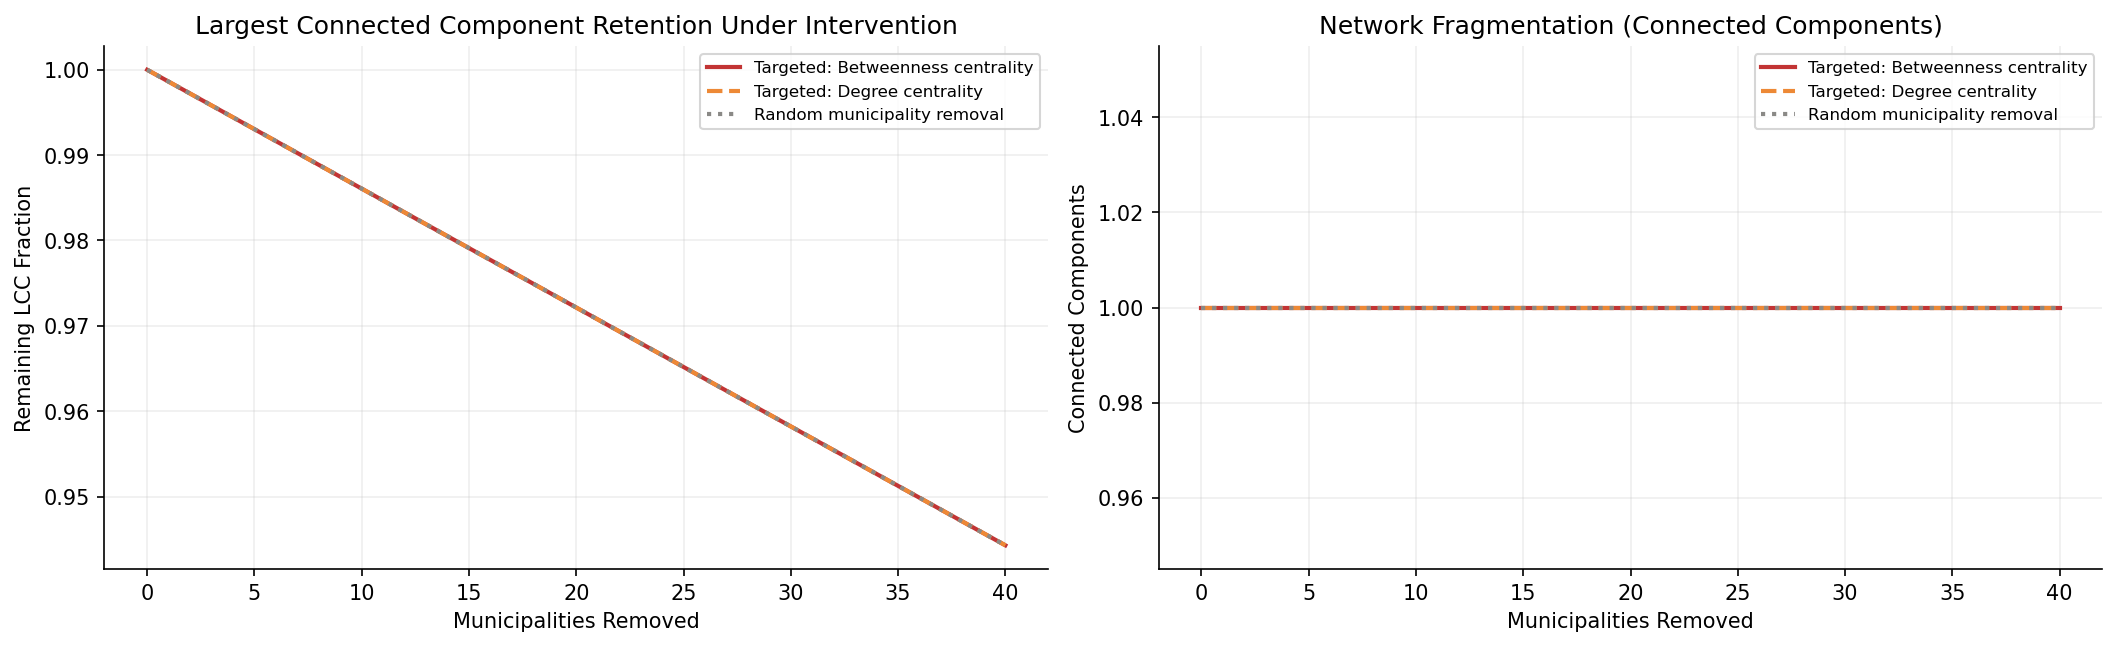

In [ ]:
g_2010_full = networks_by_year[2010]
active_2010 = g_2010_full.subgraph([n for n in g_2010_full if g_2010_full.degree(n) > 0]).copy()

deg_cent = nx.degree_centrality(active_2010)
bet_cent = nx.betweenness_centrality(active_2010)

mun_centrality = pd.DataFrame([
    {
        "municipality": active_2010.nodes[n]["code"],
        "state": state_names.get(active_2010.nodes[n]["state"], active_2010.nodes[n]["state"]),
        "cartels_present": active_2010.degree(n),
        "degree_centrality": deg_cent[n],
        "betweenness_centrality": bet_cent[n],
    }
    for n in active_2010
    if active_2010.nodes[n]["bipartite"] == 0
]).sort_values("betweenness_centrality", ascending=False)

print("Top 10 Bridge Municipalities by Betweenness Centrality (2010):")
display(mun_centrality.head(10).round(4))

def simulate_municipality_removal(graph, ordered_nodes, steps=30):
    g = graph.copy()
    initial_lcc = len(max(nx.connected_components(g), key=len, default=set()))
    records = [{"removed": 0, "lcc_fraction": 1.0, "components": nx.number_connected_components(g)}]
    for k, node in enumerate(ordered_nodes[:steps], start=1):
        if node in g:
            g.remove_node(node)
        lcc = len(max(nx.connected_components(g), key=len, default=set())) if g.number_of_nodes() else 0
        records.append({
            "removed": k,
            "lcc_fraction": lcc / initial_lcc if initial_lcc else 0.0,
            "components": nx.number_connected_components(g) if g.number_of_nodes() else 0,
        })
    return pd.DataFrame(records)

mun_nodes_sorted_bet = [
    f"municipality:{code}" for code in mun_centrality["municipality"]
]
mun_nodes_sorted_deg = [
    f"municipality:{code}"
    for code in mun_centrality.sort_values("cartels_present", ascending=False)["municipality"]
]
rng_sim = np.random.default_rng(42)
mun_nodes_random = list(rng_sim.permutation(mun_nodes_sorted_bet))

max_steps = min(40, len(mun_nodes_sorted_bet))
sim_bet = simulate_municipality_removal(active_2010, mun_nodes_sorted_bet, steps=max_steps)
sim_deg = simulate_municipality_removal(active_2010, mun_nodes_sorted_deg, steps=max_steps)
sim_rnd = simulate_municipality_removal(active_2010, mun_nodes_random, steps=max_steps)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for sim_df, label, color, ls in [
    (sim_bet, "Targeted: Betweenness centrality", "#c23434", "-"),
    (sim_deg, "Targeted: Degree centrality", "#ed8936", "--"),
    (sim_rnd, "Random municipality removal", "#8a8986", ":"),
]:
    axes[0].plot(sim_df["removed"], sim_df["lcc_fraction"], label=label, color=color, ls=ls, lw=2)
    axes[1].plot(sim_df["removed"], sim_df["components"], label=label, color=color, ls=ls, lw=2)

axes[0].set(title="Largest Connected Component Retention Under Intervention", xlabel="Municipalities Removed", ylabel="Remaining LCC Fraction")
axes[1].set(title="Network Fragmentation (Connected Components)", xlabel="Municipalities Removed", ylabel="Connected Components")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

## 6. Summary of Findings & Limitations

**Core Answer:** Temporal network structure and territorial rivalry predict where new cartel–municipality associations **form**, whereas persistence (consecutive years present) rather than rival displacement drives whether existing associations **disappear**.

- **H1 (Within-state path dependence — supported):** New associations form roughly 5 times more often when the focal cartel already operates elsewhere in the same state, and the adjusted odds ratio remains strongly positive (~2.0) after controlling for history, degrees, cartel, and year fixed effects.
- **H2 (Rival deterrence vs. co-presence — supported):** While occupied municipalities attract more activity overall than isolated ones, the presence of an avoiding rival ($z \le -1.96$) cuts the adjusted odds of new link formation roughly in half. Adding territorial rivalry features significantly improves out-of-sample Average Precision in 2009–2010 over both generic structural features and history-only baselines.
- **H3 (Displacement / disappearance — not supported):** Avoiding rivals do not increase link disappearance; instead, disappearance declines sharply with consecutive years of prior presence (`years_present`) and overall reporting density over time.
- **H4 (Cartel heterogeneity — partly supported):** Within-state expansion and entry into contested vs. uncontested municipalities differ markedly across cartels (e.g., strong regional clustering for Familia and Zetas vs. broader contested entry for Sinaloa).
- **Intervention & Mesoscale Takeaways:** Noise-corrected backboning reveals spatially coherent municipality communities aligned with state borders, and centrality-targeted interventions fragment the active bipartite network substantially faster than random removal.

**Key Limitations:** Edges reflect web-reported associations rather than confirmed territorial control; administrative states are coarse spatial proxies; and historical reporting intensity increases sharply over 1990–2010, requiring careful distinction between true link emergence and improved media coverage.